# Puntos agrícolas persistentes y representativos de México

**Fuente principal:** Conjuntos de datos vectoriales de Uso del Suelo y Vegetación (USyV)
escala 1:250 000 del INEGI, Series I a VII (≈1980–2018).

Esta libreta revisa todos los mapas del INEGI disponibles en `data/pure` y `data/raw` y
construye un conjunto de puntos de zonas agrícolas que cumple cinco criterios:

1. **Persistencia.** Cada punto es zona agrícola en las 7 series. Los puntos *estables*
   conservan exactamente la misma clase en todas las series.
2. **Todos los tipos.** Están representadas las 18 clases agrícolas del INEGI
   (régimen Riego/Temporal/Humedad × ciclo Anual/Semipermanente/Permanente y combinaciones).
3. **Cobertura nacional.** La selección está balanceada en el espacio y cubre todos los
   estados que tienen agricultura persistente.
4. **Significancia productiva.** Se descartan los puntos en municipios sin producción
   en su modalidad y se pondera con la superficie sembrada municipal del SIAP (2003–2025).
5. **Seguimiento de cambios.** También se incluyen los puntos que cambiaron de ciclo
   y/o de régimen; se documenta su trayectoria serie por serie, sin excluir las oscilantes.

El número de puntos no se fija de antemano. Se elige el menor tamaño de muestra que
reproduce la distribución nacional según una **curva de representatividad** (sección 9).

**Flujo:** inventario → sistemas de referencia → armonización → exploración → candidatos →
trayectorias → contexto SIAP → diseño muestral → curva de representatividad → muestra
final → exportación.

## 0. Configuración

In [1]:
from collections import Counter
import io
import re
import unicodedata
import warnings
import zipfile

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyogrio
from pyproj import CRS, Transformer
from rasterio import features
from rasterio.transform import from_origin
import shapely

from scripts.config import DATA_DIR

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

PURE = DATA_DIR / "pure" / "INEGI"
RAW = DATA_DIR / "raw" / "INEGI"
INTERM = DATA_DIR / "interm" / "INEGI"
PROCESS = DATA_DIR / "process" / "INEGI"
SIAP_DIR = DATA_DIR / "process" / "DGSIAP"
MARCO = RAW / "Mexico" / "Mexico" / "conjunto_de_datos"
for carpeta in (INTERM, PROCESS):
    carpeta.mkdir(parents=True, exist_ok=True)

# Sistemas de referencia
CRS_TRABAJO = "EPSG:6372"  # LCC ITRF2008, el del Marco Geoestadístico
CRS_SALIDA = "EPSG:4326"
LCC_INEGI = (
    "+proj=lcc +ellps=GRS80 +lat_0=12 +lon_0=-102 +lat_1=17.5 +lat_2=29.5 "
    "+x_0=2500000 +y_0=0 +units=m +no_defs"
)

# Construcción de candidatos
GRID_M = 1000          # malla base: celdas de 1 km²
GRID_FINO_M = 250      # malla densificada para las clases raras
MIN_CAND_CLASE = 400   # clases con menos candidatos a 1 km se densifican
DIST_MIN = 250         # m: 2 × tolerancia gráfica de 1:250k (0.5 mm × 250 000 = 125 m)
DIST_PREF = 500        # m: distancia al borde preferida (duplica el peso de muestreo)

# Muestreo
SEED = 2026
ALFA = 0.5             # asignación ∝ área^ALFA (0.5 = raíz cuadrada)
N_MIN_ESTABLE = 3      # mínimo de puntos por clase estable
N_MIN_CAMBIO = 1       # mínimo de puntos por estrato de cambio
MIN_CAND_ESTRATO = 30  # estratos de cambio más chicos se agrupan en "otros"
N_GRID = [100, 200, 300, 500, 750, 1000, 1500, 2000, 3000]
SEMILLAS = 5
UMBRALES = {
    "tvd_clase": 0.05,        # distancia de variación total, clase final
    "tvd_estado": 0.05,       # distancia de variación total, entidad federativa
    "tvd_trayectoria": 0.05,  # distancia de variación total, estado de trayectoria
    "err_regimen": 0.05,      # error relativo máximo de superficie Riego/Temporal
    "p95_dist_km": 50,        # el 95 % del área persistente a ≤ 50 km de un punto
    "cobertura_siap": 0.50,   # fracción de la superficie sembrada nacional cubierta
}

# Series USyV 1:250 000 que se usan (año aproximado de los insumos)
SERIES = {
    "I": {"anio": 1980, "periodo": "1968–1986", "esquema": "s12", "encoding": "ISO-8859-1",
          "ruta": PURE / "702825007020_s/conjunto_de_datos/us250s1v_lcc.shp"},
    "II": {"anio": 1993, "periodo": "1993", "esquema": "s12",
           "ruta": PURE / "702825007021_s/conjunto_de_datos/us250s2v_lcc.shp"},
    "III": {"anio": 2002, "periodo": "2002", "esquema": "g", "clave": "CLAVE",
            "ruta": PURE / "702825007022_s/shp/us250s3g/us250s3g.shp"},
    "IV": {"anio": 2007, "periodo": "2007", "esquema": "g", "clave": "CVE_G",
           "ruta": PURE / "702825007023_s/shape/us250s4g/us250s4g.shp"},
    "V": {"anio": 2011, "periodo": "2011", "esquema": "g", "clave": "CVE_G",
          "ruta": PURE / "702825007024_s/conjunto_de_datos/CAPAS/usv250s5g/usv250s5g.shp"},
    "VI": {"anio": 2014, "periodo": "2014", "esquema": "union", "clave": "CVE_UNION",
           "ruta": PURE / "889463598459_s/conjunto_de_datos/usv250s6_union.shp"},
    "VII": {"anio": 2018, "periodo": "2018", "esquema": "union", "clave": "CLAVE",
            "ruta": RAW / "UsoSueloMexico/conjunto_de_datos/cdv_usuev250sVII_cnal.shp"},
}
SER = list(SERIES)
ANIO = {s: info["anio"] for s, info in SERIES.items()}
pd.DataFrame(SERIES).T[["anio", "periodo", "esquema", "ruta"]]

,anio,periodo,esquema,ruta
I,1980,1968–1986,s12,/home/david/Documents/Repositories/academica/p...
II,1993,1993,s12,/home/david/Documents/Repositories/academica/p...
III,2002,2002,g,/home/david/Documents/Repositories/academica/p...
IV,2007,2007,g,/home/david/Documents/Repositories/academica/p...
V,2011,2011,g,/home/david/Documents/Repositories/academica/p...
VI,2014,2014,union,/home/david/Documents/Repositories/academica/p...
VII,2018,2018,union,/home/david/Documents/Repositories/academica/p...


## 1. Inventario de los mapas del INEGI

Se revisan todos los shapefiles de `data/pure/INEGI` y `data/raw/INEGI`, incluidos los que
siguen comprimidos. Éstos se leen directamente del zip mediante `/vsizip/` de GDAL, sin
extraerlos. De cada capa se obtiene la geometría, el número de elementos, el sistema de
referencia y los campos.

In [2]:
SERIE_POR_PRODUCTO = {
    "702825007020": "Serie I", "702825007021": "Serie II",
    "702825007022": "Serie III", "702825007023": "Serie IV",
    "702825007024": "Serie V", "889463598459": "Serie VI",
    "889463173359": "Serie VI (capa unión, versión 03/2017)",
    "889463842781": "Serie VII", "UsoSueloMexico": "Serie VII",
    "702825267865": "Serie II 1:1 000 000", "Mexico": "Marco Geoestadístico 2025",
}
# Descripción inferida de los campos de cada capa y de los diccionarios del INEGI
LEYENDA_CAPAS = {
    "v": "Uso del suelo y vegetación (capa principal de polígonos)",
    "g": "Agroecosistemas: tipo de agricultura y ciclo de cultivo (TIPAGES, TIP_CUL1-2)",
    "union": "Capa integrada de uso del suelo y vegetación (clave + DESCRIPCIO)",
    "a": "Información fisonómica complementaria (ASPECTO) / puntos auxiliares en S-II",
    "c": "Puntos de verificación de campo: cultivos observados",
    "d": "Desarrollo de la vegetación y cobertura arbórea (DESVEG, COB_ARB)",
    "e": "Puntos de verificación de campo: especies vegetales",
    "f": "Puntos de actividad forestal",
    "h": "Altura de la vegetación (ALTURA)",
    "i": "Vegetación puntual (menor a la unidad mínima cartografiable)",
    "l": "Vegetación lineal",
    "n": "Nomadismo agrícola (NOMA_AGR en S-III a S-V) / capa complementaria",
    "o": "Puntos de otras actividades",
    "p": "Puntos de actividad pecuaria (T_GANADO)",
    "r": "Erosión (EROSION)",
    "00ent": "Marco Geoestadístico: entidades federativas",
    "00mun": "Marco Geoestadístico: municipios",
}


def nombre_crs(crs):
    return CRS.from_user_input(crs).name if crs else "sin CRS reconocible"


def tipo_capa(nombre):
    nombre = nombre.lower()
    if "union" in nombre or "usuev250svii" in nombre:
        return "union"
    if nombre.startswith("uso del suelo"):
        return "v"
    if nombre in ("00ent", "00mun"):
        return nombre
    coincide = re.match(r"usv?250s\d([a-z])", nombre)
    return coincide.group(1) if coincide else "?"


def producto_de(ruta):
    coincide = re.search(r"(\d{12})_s", ruta)
    if coincide:
        return coincide.group(1)
    return "UsoSueloMexico" if "UsoSueloMexico" in ruta else "Mexico"


def rutas_shapefile():
    # (etapa, contenedor, ruta legible por GDAL)
    for base in (PURE, RAW):
        etapa = base.parent.name
        for shp in sorted(base.rglob("*.shp")):
            yield etapa, "carpeta", str(shp)
        for zp in sorted(base.glob("*.zip")):
            with zipfile.ZipFile(zp) as z:
                for nombre in z.namelist():
                    if nombre.lower().endswith(".shp"):
                        yield etapa, "zip", f"/vsizip/{zp}/{nombre}"
                    elif nombre.lower().endswith(".zip"):
                        interno = zipfile.ZipFile(io.BytesIO(z.read(nombre)))
                        for sub in interno.namelist():
                            if sub.lower().endswith(".shp"):
                                yield etapa, "zip anidado", f"/vsizip/{{/vsizip/{zp}/{nombre}}}/{sub}"


filas = []
for etapa, contenedor, ruta in rutas_shapefile():
    info = pyogrio.read_info(ruta)
    capa = re.split(r"[/}]", ruta)[-1].removesuffix(".shp")
    producto = producto_de(ruta)
    filas.append({
        "etapa": etapa, "contenedor": contenedor, "producto": producto,
        "serie": SERIE_POR_PRODUCTO.get(producto, "?"), "capa": capa,
        "tipo_capa": tipo_capa(capa), "geometria": info["geometry_type"],
        "elementos": info["features"], "crs": nombre_crs(info["crs"]),
        "n_campos": len(info["fields"]), "campos": ", ".join(info["fields"]),
        "ruta": ruta,
    })
inventario = pd.DataFrame(filas)
inventario["descripcion"] = inventario["tipo_capa"].map(LEYENDA_CAPAS).fillna("")
# Una capa es duplicada si ya apareció antes con el mismo producto, nombre y número de elementos
inventario["duplicado"] = inventario.duplicated(["serie", "capa", "elementos"], keep="first")
print(f"Capas encontradas: {len(inventario)}  (únicas: {(~inventario.duplicado).sum()}, "
      f"duplicadas: {inventario.duplicado.sum()})")
inventario.groupby(["serie", "etapa", "contenedor"]).size().rename("capas").to_frame()

Capas encontradas: 128  (únicas: 65, duplicadas: 63)


capas
serie                                  etapa contenedor        
Marco Geoestadístico 2025              raw   carpeta          2
Serie I                                pure  carpeta          1
                                       raw   zip              1
Serie II                               pure  carpeta          5
                                       raw   zip              5
Serie II 1:1 000 000                   pure  zip anidado      1
Serie III                              pure  carpeta         14
                                       raw   zip             14
Serie IV                               pure  carpeta         13
                                       raw   zip             13
Serie V                                pure  carpeta         13
                                       raw   zip             13
Serie VI                               pure  carpeta         14
                                       raw   zip             14
Serie VI (capa unión, versión 03/2017) pure  zip              1
Serie VII                              pure  zip              2
                                       raw   carpeta          2

In [3]:
cols = ["serie", "etapa", "contenedor", "capa", "tipo_capa", "descripcion",
        "geometria", "elementos", "crs", "n_campos"]
inventario.loc[~inventario.duplicado, cols].reset_index(drop=True)

,serie,etapa,contenedor,capa,tipo_capa,descripcion,geometria,elementos,crs,n_campos
0,Serie I,pure,carpeta,us250s1v_lcc,v,Uso del suelo y vegetación (capa principal de ...,Polygon,141289,sin CRS reconocible,15
1,Serie II,pure,carpeta,us250s2a_lcc,a,Información fisonómica complementaria (ASPECTO...,Point,6010,sin CRS reconocible,14
2,Serie II,pure,carpeta,us250s2c_lcc,c,Puntos de verificación de campo: cultivos obse...,Point,6514,sin CRS reconocible,21
3,Serie II,pure,carpeta,us250s2e_lcc,e,Puntos de verificación de campo: especies vege...,Point,5630,sin CRS reconocible,25
4,Serie II,pure,carpeta,us250s2n_lcc,n,Nomadismo agrícola (NOMA_AGR en S-III a S-V) /...,Polygon,2729,sin CRS reconocible,7
...,...,...,...,...,...,...,...,...,...,...
60,Serie II 1:1 000 000,pure,zip anidado,Uso del suelo y vegetacion,v,Uso del suelo y vegetación (capa principal de ...,Polygon,26866,North_America_Lambert_Conformal_Conic,13
61,"Serie VI (capa unión, versión 03/2017)",pure,zip,usv250s6_union,union,Capa integrada de uso del suelo y vegetación (...,Polygon,142760,ITRF_1992_Lambert_Conformal_Conic,4
62,Serie VII,pure,zip,cdv_usuev250sVII_cnal,union,Capa integrada de uso del suelo y vegetación (...,Polygon,179099,Albers_Conic_Equal_Area,2
63,Marco Geoestadístico 2025,raw,carpeta,00ent,00ent,Marco Geoestadístico: entidades federativas,Polygon,32,Mexico ITRF2008 / LCC,3


In [4]:
# Campos de las capas que contienen información agrícola por serie
agricolas = inventario[~inventario.duplicado & inventario.tipo_capa.isin(["v", "g", "union"])]
agricolas[["serie", "capa", "tipo_capa", "elementos", "campos"]].reset_index(drop=True)

,serie,capa,tipo_capa,elementos,campos
0,Serie I,us250s1v_lcc,v,141289,"AREA, PERIMETER, US250S1V_, US250S1V_I, FC, CL..."
1,Serie II,us250s2v_lcc,v,139153,"AREA, PERIMETER, US250S2V_, US250S2V_I, FC, CL..."
2,Serie III,us250s3g,g,50855,"AREA, PERIMETER, US250S3G_, US250S3G_I, CLAVE,..."
3,Serie III,us250s3v,v,106057,"AREA, PERIMETER, USV250S3V_, USV250S3V1, CLAVE..."
4,Serie IV,us250s4g,g,55064,"US250S4G_I, CVE_G, CODIGO, TIP_INFO, AGECOSIS,..."
5,Serie IV,us250s4v,v,110682,"US250S4V_I, CVE_V, CLAVEFOT, CODIGO, TIP_INFO,..."
6,Serie V,usv250s5g,g,56846,"OBJECTID, CVE_G, CODIGO, TIP_INFO, AGECOSIS, T..."
7,Serie V,usv250s5v,v,111495,"OBJECTID, CVE_V, TIP_INFO, TIP_ECOV, TIP_VEG, ..."
8,Serie VI,usv250s6_union,union,148294,"OBJECTID, CVE_UNION, DESCRIPCIO"
9,Serie VI,usv250s6g,g,71967,"TIP_INFO, CLAVE, TIPAGES, TIP_CUL1, TIP_CUL2, ..."


### Qué capa se usa en cada serie y por qué

| Serie | Capa | Cómo se identifica la agricultura |
|---|---|---|
| I, II | `us250s{1,2}v` (v) | `TIPO` ∈ {temporal, riego, riego eventual, humedad} + `CULT_PRI`/`CULT_SEC` |
| III, IV, V | `us250s{3,4}g`, `usv250s5g` (g) | `TIPAGES` = AGRICULTURA DE … + `TIP_CUL1`/`TIP_CUL2` |
| VI | `usv250s6_union` | `DESCRIPCIO` = AGRICULTURA DE … |
| VII | `cdv_usuev250sVII_cnal` | `DESCRIPCIO` = AGRICULTURA DE … |

- En las series III a V la capa `v` agrupa toda la agricultura en una sola clave (`IAPF`),
  así que el régimen y el ciclo sólo se pueden obtener de la capa `g` (agroecosistemas).
- **Capas que no se usan para construir los puntos:**
  - *Serie II 1:1 000 000* (`702825267865_s.zip`): tiene otra escala y su información ya
    está en la Serie II 1:250 000.
  - *Serie VI, capa unión 03/2017* (`889463173359_s.zip`): es una versión anterior de la
    capa unión de `889463598459_s`.
  - `889463842781_s.zip`, `UsoSueloMexico.zip` y `raw/INEGI/UsoSueloMexico/UsoSueloMexico`:
    son copias de la Serie VII.
  - Los zips de `data/raw/INEGI` son copias de las carpetas extraídas en `data/pure/INEGI`.
  - Las capas de puntos (`c`, `e`, `f`, `i`, `o`, `p`), las de líneas (`l`) y los polígonos
    complementarios (`a`, `d`, `h`, `n`, `r`) no describen el régimen ni el ciclo agrícola.
- *Pastizal cultivado* (PC) y *bosque cultivado* (BC) se excluyen: sólo se usan las
  18 clases agrícolas.

## 2. Sistemas de referencia

- **Series I y II.** Su `.prj` es una cadena proj4 que GDAL no reconoce, así que la capa
  se lee sin sistema de referencia. Se les asigna la proyección cónica conforme de
  Lambert del INEGI, con los mismos parámetros que las series III a VI.
- **Series III a VI.** Están en LCC ITRF92.
- **Serie VII.** Declara una proyección Albers. Se comprueba (en la sección 3) que de
  verdad está en Albers y que no es una LCC mal etiquetada.

Todo se reproyecta a EPSG:6372 (LCC ITRF2008), el sistema del Marco Geoestadístico.

In [5]:
for serie in ("I", "II"):
    prj = SERIES[serie]["ruta"].with_suffix(".prj").read_text().split()
    print(f"Serie {serie} .prj:", " ".join(prj))
print()
for serie, info in SERIES.items():
    print(f"Serie {serie:>3}: {nombre_crs(pyogrio.read_info(info['ruta'])['crs'])}")

limites = pd.DataFrame(
    {s: pyogrio.read_info(info["ruta"])["total_bounds"] for s, info in SERIES.items()},
    index=["xmin", "ymin", "xmax", "ymax"],
).T.round(0)
limites

Serie I .prj: +proj=lcc +ellps=GRS80 +lat_0=12 +lon_0=-102 +lat_1=17.5 +lat_2=29.5 +x_0=2500000
Serie II .prj: +proj=lcc +ellps=GRS80 +lat_0=12 +lon_0=-102 +lat_1=17.5 +lat_2=29.5 +x_0=2500000

Serie   I: sin CRS reconocible
Serie  II: sin CRS reconocible
Serie III: ITRF_1992_Lambert_Conformal_Conic
Serie  IV: ITRF_1992_Lambert_Conformal_Conic
Serie   V: ITRF_1992_Lambert_Conformal_Conic
Serie  VI: ITRF_1992_Lambert_Conformal_Conic
Serie VII: Albers_Conic_Equal_Area


,xmin,ymin,xmax,ymax
I,542659.0,18649.0,4311581.0,2367041.0
II,542659.0,18649.0,4311581.0,2438126.0
III,738402.0,248022.0,4189510.0,2410301.0
IV,957837.0,248139.0,4189413.0,2410319.0
V,738316.0,248140.0,4189413.0,2410301.0
VI,738394.0,248140.0,4189413.0,2367041.0
VII,738425.0,243167.0,4189503.0,2366103.0


## 3. Carga y armonización de la capa agrícola

Las claves de las siete series se reducen a una sola clasificación de 18 clases:

```
clase = régimen {R: riego, T: temporal, H: humedad} + ciclos {A: anual, S: semipermanente, P: permanente}
```

Los ciclos se ordenan siempre como A < S < P. Por ejemplo, la clave `TPA` de las series
I y II (permanente con anual) equivale a `TAP` en las series III a VII.

- `riego eventual` (series I y II) se considera riego.
- `riego suspendido` no tiene ciclo de cultivo y se excluye.
- En las series I y II el tercer cultivo (`CULT_TER`) no se usa, porque las series
  posteriores sólo registran dos.

Las capas armonizadas se guardan en `data/interm/INEGI/usv_agri_serie_*.parquet`.

In [6]:
CICLOS = {"ANUAL": "A", "SEMIPERMANENTE": "S", "PERMANENTE": "P"}
REGIMENES = {"RIEGO": "R", "RIEGO EVENTUAL": "R", "TEMPORAL": "T", "HUMEDAD": "H"}
ORDEN_CICLO = "ASP"
NOMBRE_REGIMEN = {"R": "RIEGO", "T": "TEMPORAL", "H": "HUMEDAD"}
NOMBRE_CICLO = {"A": "ANUAL", "S": "SEMIPERMANENTE", "P": "PERMANENTE"}
CICLOS_VALIDOS = ["A", "S", "P", "AS", "AP", "SP"]
CLASES = [r + c for r in "TRH" for c in CICLOS_VALIDOS]
DESCRIPCION = {
    r + c: f"AGRICULTURA DE {NOMBRE_REGIMEN[r]} " + " Y ".join(NOMBRE_CICLO[x] for x in c)
    for r in "TRH" for c in CICLOS_VALIDOS
}


def normalizar(serie):
    def sin_acentos(texto):
        if not isinstance(texto, str):
            return texto
        texto = unicodedata.normalize("NFKD", texto)
        return "".join(ch for ch in texto if not unicodedata.combining(ch)).upper().strip()
    return serie.map(sin_acentos)


def ciclo_canonico(c1, c2):
    presentes = {c for c in (c1, c2) if isinstance(c, str)}
    return "".join(c for c in ORDEN_CICLO if c in presentes)


def armonizar(gdf, serie, clave, regimen, c1, c2):
    out = gpd.GeoDataFrame(
        {"serie": serie, "clave_orig": clave.to_numpy(), "regimen": regimen.to_numpy(),
         "ciclo": [ciclo_canonico(a, b) for a, b in zip(c1, c2)]},
        geometry=gdf.geometry.to_numpy(), crs=gdf.crs,
    )
    out = out[out["regimen"].notna() & out["ciclo"].ne("")].copy()
    out["clase"] = out["regimen"] + out["ciclo"]
    return out.to_crs(CRS_TRABAJO).reset_index(drop=True)


def cargar_s12(serie, info):
    gdf = gpd.read_file(info["ruta"], columns=["CLAVEFOT", "TIPO", "CULT_PRI", "CULT_SEC"],
                        encoding=info.get("encoding"))
    gdf = gdf.set_crs(LCC_INEGI, allow_override=True)
    regimen = normalizar(gdf["TIPO"]).map(REGIMENES)
    return armonizar(gdf, serie, gdf["CLAVEFOT"], regimen,
                     normalizar(gdf["CULT_PRI"]).map(CICLOS),
                     normalizar(gdf["CULT_SEC"]).map(CICLOS))


def cargar_g(serie, info):
    k = info["clave"]
    gdf = gpd.read_file(info["ruta"], columns=[k, "TIPAGES", "TIP_CUL1", "TIP_CUL2"])
    tipo = normalizar(gdf["TIPAGES"]).str.extract(r"^AGRICULTURA DE (RIEGO|TEMPORAL|HUMEDAD)$")[0]
    return armonizar(gdf, serie, gdf[k], tipo.map(REGIMENES),
                     normalizar(gdf["TIP_CUL1"]).map(CICLOS),
                     normalizar(gdf["TIP_CUL2"]).map(CICLOS))


def cargar_union(serie, info):
    k = info["clave"]
    gdf = gpd.read_file(info["ruta"], columns=[k, "DESCRIPCIO"])
    partes = normalizar(gdf["DESCRIPCIO"]).str.extract(
        r"^AGRICULTURA DE (RIEGO|TEMPORAL|HUMEDAD) (\w+)(?: Y (\w+))?$")
    return armonizar(gdf, serie, gdf[k], partes[0].map(REGIMENES),
                     partes[1].map(CICLOS), partes[2].map(CICLOS))


CARGADORES = {"s12": cargar_s12, "g": cargar_g, "union": cargar_union}


def cargar_serie(serie):
    cache = INTERM / f"usv_agri_serie_{serie}.parquet"
    if cache.exists():
        return gpd.read_parquet(cache)
    gdf = CARGADORES[SERIES[serie]["esquema"]](serie, SERIES[serie])
    assert set(gdf["clase"]) <= set(CLASES), set(gdf["clase"]) - set(CLASES)
    gdf.to_parquet(cache)
    return gdf


AGRI = {s: cargar_serie(s) for s in SER}
pd.DataFrame({s: {"poligonos": len(g), "clases": g.clase.nunique(),
                  "superficie_km2": round(g.area.sum() / 1e6)} for s, g in AGRI.items()}).T

,poligonos,clases,superficie_km2
I,29784,18,257880
II,26839,18,288818
III,22452,18,309302
IV,22673,18,321620
V,22901,18,325968
VI,28169,18,328541
VII,35667,18,330611


In [7]:
# Tabla de equivalencias: claves originales que forman cada clase armonizada
equivalencias = (
    pd.concat([g[["clave_orig", "clase"]].assign(serie=s) for s, g in AGRI.items()])
    .groupby(["clase", "serie"])["clave_orig"]
    .agg(lambda v: ", ".join(sorted(set(map(str, v)))))
    .unstack("serie").reindex(index=CLASES, columns=SER)
)
equivalencias.insert(0, "descripcion", equivalencias.index.map(DESCRIPCION))
equivalencias

serie,descripcion,I,II,III,IV,V,VI,VII
clase,,,,,,,,
TA,AGRICULTURA DE TEMPORAL ANUAL,"E-TA, TA","E-TA, TA",TA,TA,TA,TA,TA
TS,AGRICULTURA DE TEMPORAL SEMIPERMANENTE,TS,TS,TS,TS,TS,TS,TS
TP,AGRICULTURA DE TEMPORAL PERMANENTE,"E-TP, TP","E-TP, TP",TP,TP,TP,TP,TP
TAS,AGRICULTURA DE TEMPORAL ANUAL Y SEMIPERMANENTE,"TAS, TASP, TSA, TSAP","TAS, TASP, TSA, TSAP",TAS,TAS,TAS,TAS,TAS
TAP,AGRICULTURA DE TEMPORAL ANUAL Y PERMANENTE,"E-TAP, E-TPA, TAP, TAPS, TPA, TPAS","E-TAP, E-TPA, TAP, TAPS, TPA, TPAS",TAP,TAP,TAP,TAP,TAP
TSP,AGRICULTURA DE TEMPORAL SEMIPERMANENTE Y PERMA...,"TPS, TPSA, TSP, TSPA","E-TSPA, TPS, TPSA, TSP, TSPA",TSP,TSP,TSP,TSP,TSP
RA,AGRICULTURA DE RIEGO ANUAL,"RA, ReA","E-RA, E-ReA, RA, ReA",RA,RA,RA,RA,RA
RS,AGRICULTURA DE RIEGO SEMIPERMANENTE,"RS, ReS","RS, ReS",RS,RS,RS,RS,RS
RP,AGRICULTURA DE RIEGO PERMANENTE,"RP, ReP","RP, ReP",RP,RP,RP,RP,RP


### Comprobación: la Serie VII sí está en Albers

Se toman 3 000 puntos interiores de polígonos agrícolas de la Serie VII y se leen sus
coordenadas de dos formas: (a) como Albers, que es lo que declara el `.prj`, y (b) como si
fueran la LCC del INEGI. Gana la lectura cuyos puntos caen con más frecuencia en
agricultura de la Serie VI, que es independiente.

In [8]:
vii_crudo = gpd.read_file(SERIES["VII"]["ruta"], columns=["DESCRIPCIO"],
                          where="DESCRIPCIO LIKE 'AGRICULTURA DE%'")
muestra_vii = vii_crudo.sample(3000, random_state=SEED).representative_point()
prueba = {}
for nombre, crs in [("Albers (declarado)", vii_crudo.crs), ("LCC INEGI (alternativo)", LCC_INEGI)]:
    pts = gpd.GeoDataFrame(geometry=muestra_vii.set_crs(crs, allow_override=True)).to_crs(CRS_TRABAJO)
    dentro = gpd.sjoin(pts, AGRI["VI"][["geometry"]], how="inner", predicate="within")
    prueba[nombre] = dentro.index.nunique() / len(pts)
pd.Series(prueba, name="fraccion_en_agricultura_VI").round(3).to_frame()

,fraccion_en_agricultura_VI
Albers (declarado),0.841
LCC INEGI (alternativo),0.320


## 4. Exploración de la agricultura por serie

In [9]:
AREA = pd.concat([
    pd.DataFrame({"serie": s, "regimen": g.regimen, "ciclo": g.ciclo, "clase": g.clase,
                  "area_km2": g.area / 1e6})
    for s, g in AGRI.items()
])
area_regimen = (AREA.pivot_table(index="serie", columns="regimen", values="area_km2", aggfunc="sum")
                .reindex(index=SER, columns=["T", "R", "H"]))
area_regimen["Total"] = area_regimen.sum(axis=1)
area_regimen.insert(0, "anio", [ANIO[s] for s in area_regimen.index])
area_regimen.round(0)

regimen,anio,T,R,H,Total
serie,,,,,
I,1980,185641.0,71033.0,1205.0,257880.0
II,1993,202547.0,84026.0,2245.0,288818.0
III,2002,214579.0,92459.0,2264.0,309302.0
IV,2007,221477.0,98095.0,2048.0,321620.0
V,2011,223473.0,100431.0,2064.0,325968.0
VI,2014,224876.0,101757.0,1908.0,328541.0
VII,2018,221800.0,106960.0,1851.0,330611.0


In [10]:
area_clase = (AREA.pivot_table(index="clase", columns="serie", values="area_km2", aggfunc="sum")
              .reindex(index=CLASES, columns=SER).fillna(0))
area_clase.round(0).astype(int)

serie,I,II,III,IV,V,VI,VII
clase,,,,,,,
TA,149827,159488,168356,172457,174867,173953,169047
TS,6227,6301,7006,7939,8107,8169,8524
TP,14771,14817,13486,13860,13998,14755,14390
TAS,4612,5732,7764,7733,7973,8165,9794
TAP,8791,13573,14997,16447,15430,16789,16833
TSP,1413,2636,2970,3042,3098,3045,3212
RA,39733,48631,49108,52073,53576,54702,54680
RS,3046,3947,4683,4409,4303,4425,5952
RP,1626,2076,2597,2908,3082,3410,5678


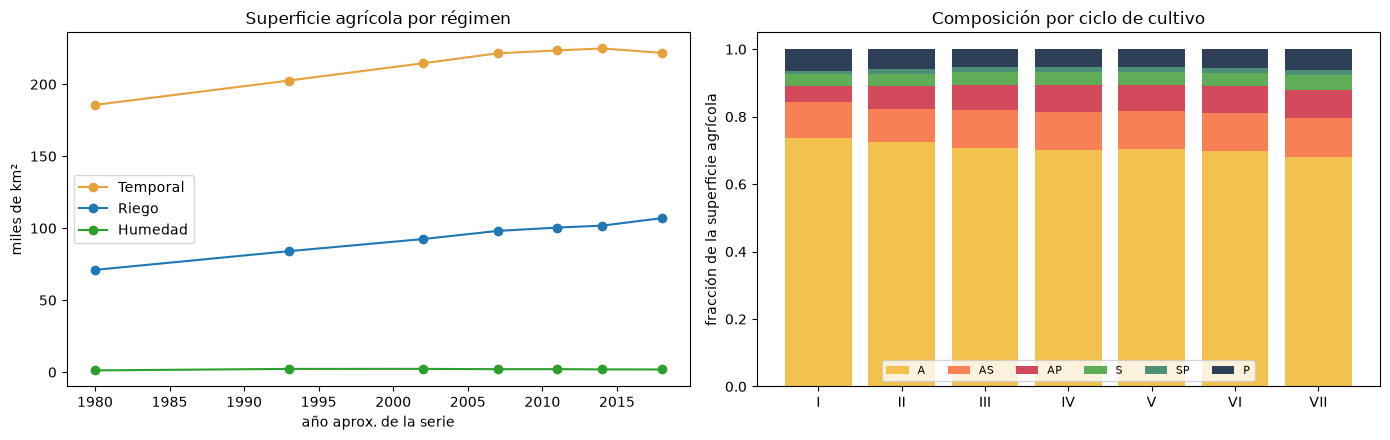

In [11]:
COLOR_REGIMEN = {"T": "#e6a03c", "R": "#1f77b4", "H": "#2ca02c"}
COLOR_CICLO = {"A": "#f2c14e", "AS": "#f78154", "AP": "#d1495b", "S": "#5fad56",
               "SP": "#4d9078", "P": "#2e4057"}
anios = [ANIO[s] for s in SER]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for r in ["T", "R", "H"]:
    axes[0].plot(anios, area_regimen[r] / 1e3, marker="o", color=COLOR_REGIMEN[r],
                 label=NOMBRE_REGIMEN[r].title())
axes[0].set(title="Superficie agrícola por régimen", ylabel="miles de km²", xlabel="año aprox. de la serie")
axes[0].legend()
area_ciclo = (AREA.pivot_table(index="serie", columns="ciclo", values="area_km2", aggfunc="sum")
              .reindex(index=SER, columns=list(COLOR_CICLO)).fillna(0))
fraccion = area_ciclo.div(area_ciclo.sum(axis=1), axis=0)
abajo = np.zeros(len(SER))
for c, color in COLOR_CICLO.items():
    axes[1].bar(SER, fraccion[c], bottom=abajo, color=color, label=c)
    abajo += fraccion[c].to_numpy()
axes[1].set(title="Composición por ciclo de cultivo", ylabel="fracción de la superficie agrícola")
axes[1].legend(ncols=6, fontsize=8, loc="lower center")
plt.tight_layout()
plt.show()

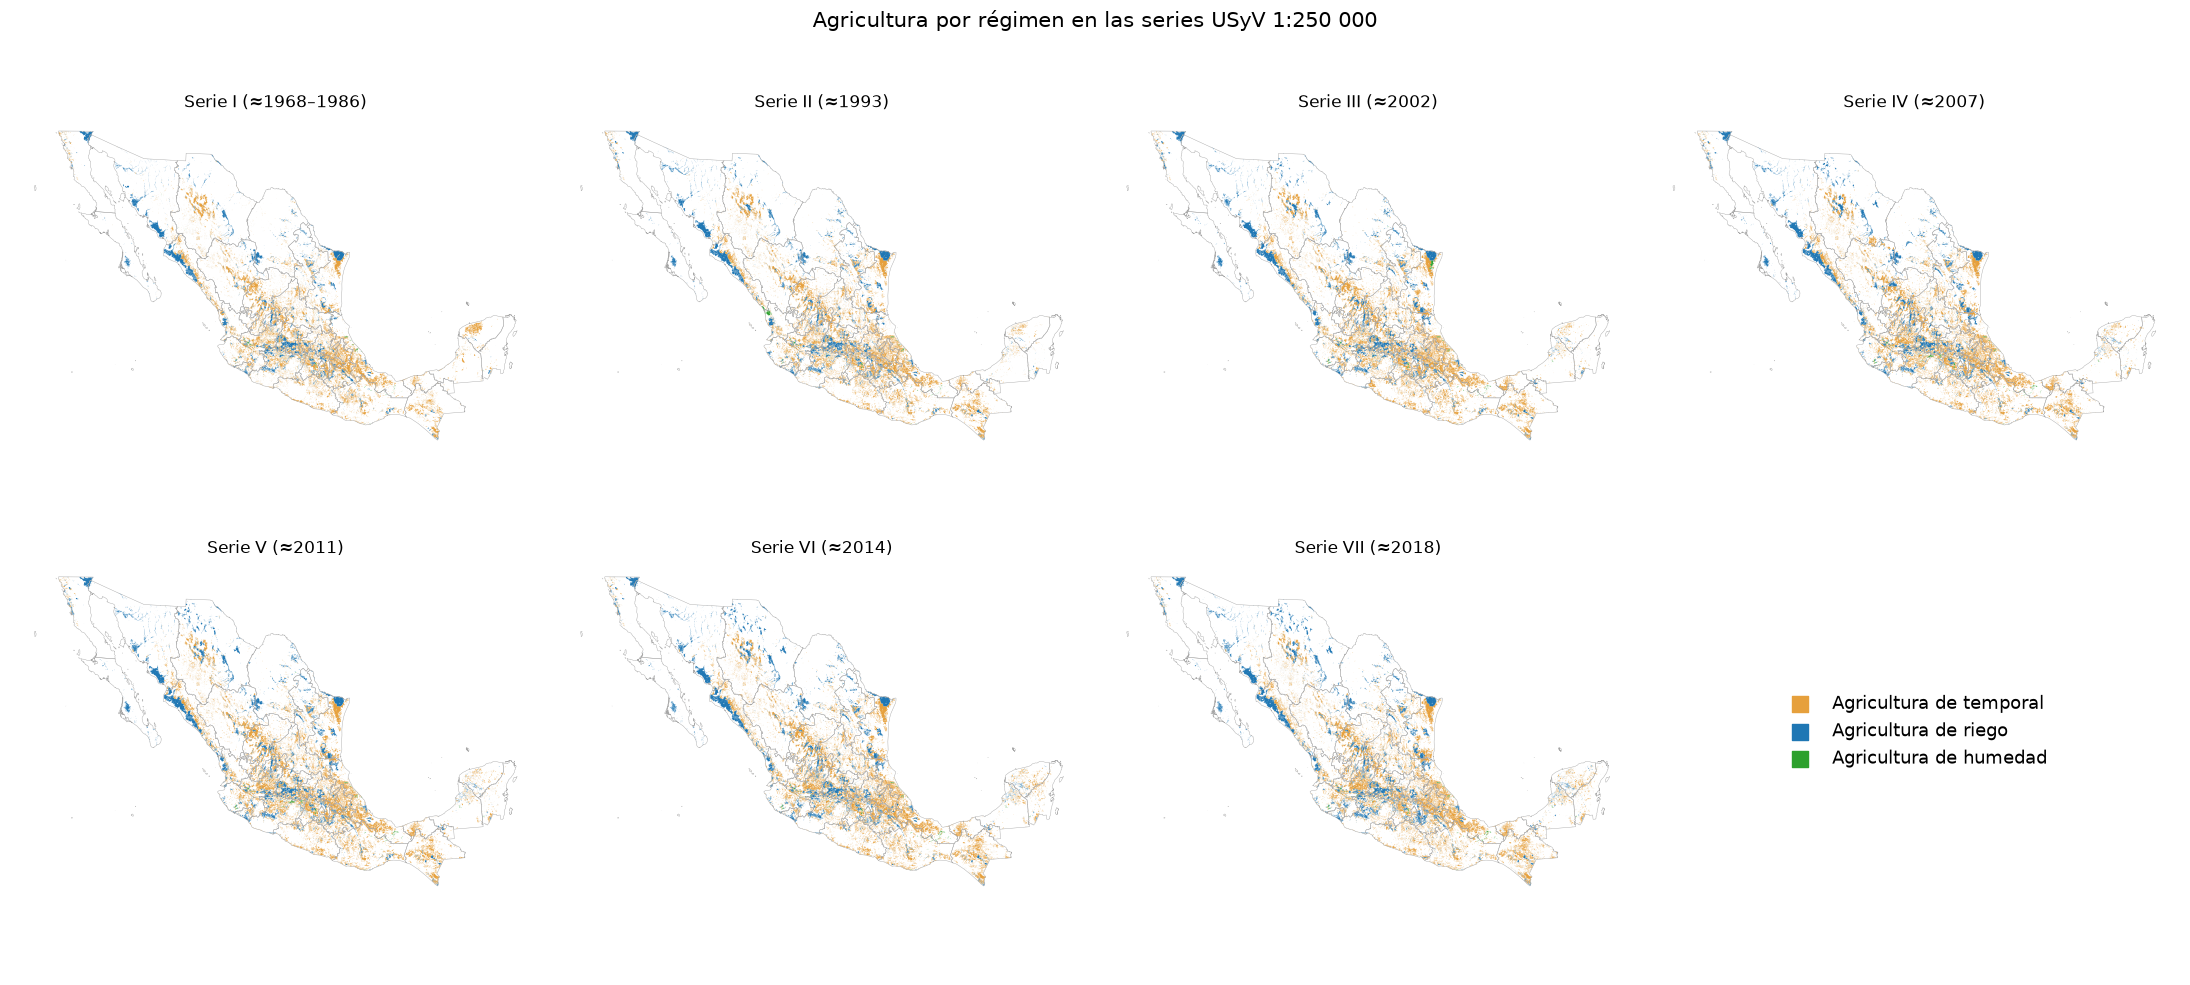

In [12]:
ENT = gpd.read_file(MARCO / "00ent.shp").to_crs(CRS_TRABAJO)
ENT_SIMPLE = ENT.assign(geometry=ENT.simplify(1000))
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
for ax, (s, g) in zip(axes.flat, AGRI.items()):
    ENT_SIMPLE.boundary.plot(ax=ax, color="0.65", lw=0.3)
    simple = g.assign(geometry=g.simplify(500))
    for r, color in COLOR_REGIMEN.items():
        simple[simple.regimen == r].plot(ax=ax, color=color, lw=0)
    ax.set_title(f"Serie {s} (≈{SERIES[s]['periodo']})")
    ax.set_axis_off()
ax = axes.flat[-1]
ax.set_axis_off()
for r, color in COLOR_REGIMEN.items():
    ax.scatter([], [], color=color, marker="s", s=120, label=f"Agricultura de {NOMBRE_REGIMEN[r].lower()}")
ax.legend(loc="center", fontsize=13, frameon=False)
plt.suptitle("Agricultura por régimen en las series USyV 1:250 000", fontsize=15)
plt.tight_layout()
plt.show()

## 5. Candidatos: persistencia agrícola en las 7 series

1. **Malla base de 1 km.** Se toman los centros de las celdas de 1 km² que caen dentro
   de la agricultura de la Serie VII (rasterización con la regla del centro). Cada
   candidato representa 1 km².
2. **Clase en cada serie.** A cada centro se le asigna la clase armonizada de cada una de
   las 7 series mediante un `sjoin(within)`. Se conservan sólo los que son agrícolas en
   las 7.
3. **Puntos interiores.** Se calcula la distancia al borde del polígono que contiene al
   punto en cada serie, y se exige `≥ DIST_MIN` en todas. Así se evitan los errores de
   posición de la escala 1:250 000 en los límites entre clases.
4. **Densificación.** Para las clases (según la Serie VII) con menos de `MIN_CAND_CLASE`
   candidatos, se repite el proceso con una malla de 250 m dentro de sus polígonos. Esos
   puntos sustituyen a los de 1 km de esas clases, de modo que cada candidato de 250 m
   representa 0.0625 km² y la población sigue siendo una partición sin traslapes.

In [13]:
def malla_dentro(gdf, paso):
    # Centros de celda (paso en m) que caen dentro de los polígonos (regla del centro)
    xmin, ymin, xmax, ymax = gdf.total_bounds
    xmin, ymin = np.floor(xmin / paso) * paso, np.floor(ymin / paso) * paso
    xmax, ymax = np.ceil(xmax / paso) * paso, np.ceil(ymax / paso) * paso
    ancho, alto = int(round((xmax - xmin) / paso)), int(round((ymax - ymin) / paso))
    mascara = features.rasterize(
        ((geom, 1) for geom in gdf.geometry), out_shape=(alto, ancho),
        transform=from_origin(xmin, ymax, paso, paso), fill=0, dtype="uint8",
    )
    filas, cols = np.nonzero(mascara)
    return xmin + (cols + 0.5) * paso, ymax - (filas + 0.5) * paso


def puntos(x, y, paso):
    return gpd.GeoDataFrame(
        {"x": x, "y": y, "malla_m": paso, "area_km2": (paso / 1000) ** 2},
        geometry=gpd.points_from_xy(x, y), crs=CRS_TRABAJO,
    )


def clasificar(pts):
    # Clase armonizada y polígono que contiene al punto en cada serie
    out = pts.copy()
    for s, g in AGRI.items():
        j = gpd.sjoin(out[["geometry"]], g[["clase", "geometry"]], how="left", predicate="within")
        j = j[~j.index.duplicated(keep="first")].reindex(out.index)
        out[f"clase_{s}"] = j["clase"]
        out[f"pol_{s}"] = j["index_right"]
    return out


def interiores(pts):
    # Distancia al borde del polígono en cada serie; se descartan los que quedan a < DIST_MIN
    out = pts.copy()
    for s, g in AGRI.items():
        unicos, inversa = np.unique(out[f"pol_{s}"].to_numpy().astype(int), return_inverse=True)
        bordes = shapely.boundary(g.geometry.to_numpy()[unicos])
        out[f"dist_{s}"] = shapely.distance(out.geometry.to_numpy(), bordes[inversa])
        out = out[out[f"dist_{s}"] >= DIST_MIN]
    out["dist_borde_min_m"] = out[[f"dist_{s}" for s in SER]].min(axis=1)
    return out.drop(columns=[f"pol_{s}" for s in SER])


COLS_CLASE = [f"clase_{s}" for s in SER]
SUFIJO = f"{GRID_M}_{GRID_FINO_M}_{DIST_MIN}_{MIN_CAND_CLASE}"
CACHE_BASE = INTERM / f"malla_base_vii_{GRID_M}.parquet"
CACHE_CAND = INTERM / f"candidatos_{SUFIJO}.parquet"
CACHE_EMBUDO = INTERM / f"embudo_{SUFIJO}.parquet"

if CACHE_BASE.exists() and CACHE_CAND.exists() and CACHE_EMBUDO.exists():
    base = gpd.read_parquet(CACHE_BASE)
    candidatos = gpd.read_parquet(CACHE_CAND)
    embudo = pd.read_parquet(CACHE_EMBUDO)
    RARAS = sorted(candidatos.loc[candidatos.malla_m == GRID_FINO_M, "clase_VII"].unique())
else:
    base = clasificar(puntos(*malla_dentro(AGRI["VII"], GRID_M), GRID_M))
    agri7 = base[base[COLS_CLASE].notna().all(axis=1)]
    cand_base = interiores(agri7)
    conteo = cand_base["clase_VII"].value_counts().reindex(CLASES, fill_value=0)
    RARAS = conteo[conteo < MIN_CAND_CLASE].index.tolist()

    poligonos_raros = AGRI["VII"][AGRI["VII"].clase.isin(RARAS)]
    fino = clasificar(puntos(*malla_dentro(poligonos_raros, GRID_FINO_M), GRID_FINO_M))
    fino = fino[fino["clase_VII"].isin(RARAS)]
    agri7_fino = fino[fino[COLS_CLASE].notna().all(axis=1)]
    cand_fino = interiores(agri7_fino)

    candidatos = pd.concat(
        [cand_base[~cand_base["clase_VII"].isin(RARAS)], cand_fino], ignore_index=True)
    etapas = ["en agricultura de la Serie VII", "agrícola en las 7 series",
              f"a ≥ {DIST_MIN} m del borde en las 7 series"]
    embudo = pd.DataFrame({
        "puntos_1km": [len(base), len(agri7), len(cand_base)],
        "area_km2_1km": [base.area_km2.sum(), agri7.area_km2.sum(), cand_base.area_km2.sum()],
        "puntos_250m_clases_raras": [len(fino), len(agri7_fino), len(cand_fino)],
        "area_km2_250m": [fino.area_km2.sum(), agri7_fino.area_km2.sum(), cand_fino.area_km2.sum()],
    }, index=etapas)
    base = base[["x", "y", "area_km2", "clase_VII", "geometry"]]
    base.to_parquet(CACHE_BASE)
    candidatos.to_parquet(CACHE_CAND)
    embudo.to_parquet(CACHE_EMBUDO)

print("Clases densificadas a 250 m:", RARAS)
print("Candidatos:", len(candidatos), "| superficie representada:",
      round(candidatos.area_km2.sum()), "km²")
embudo.round(0)

Clases densificadas a 250 m: ['HA', 'HAP', 'HAS', 'HP', 'HS', 'HSP']
Candidatos: 98031 | superficie representada: 92744 km²


,puntos_1km,area_km2_1km,puntos_250m_clases_raras,area_km2_250m
en agricultura de la Serie VII,330371,330371.0,29621,1851.0
agrícola en las 7 series,184278,184278.0,15786,987.0
a ≥ 250 m del borde en las 7 series,92765,92765.0,5639,352.0


### Columnas de seguimiento de cambios

Para cada candidato se resume su secuencia de clases I→VII:

| Columna | Significado |
|---|---|
| `clase_k`, `regimen_k`, `ciclo_k` | Clase, régimen y ciclo en la serie *k* |
| `trayectoria_clase` | Secuencia completa, p. ej. `TA→TA→TAP→TAP→TAP→TAP→TAP` |
| `clase_inicial`, `clase_final`, `clase_modal` | Clase en la Serie I, en la VII y la más frecuente (los empates se resuelven por la más reciente) |
| `n_cambios_clase`, `n_cambios_regimen`, `n_cambios_ciclo` | Número de transiciones entre series consecutivas |
| `estado_trayectoria` | `estable`, `cambio_ciclo`, `cambio_regimen` o `cambio_ambos` |
| `tipo_tray_regimen`, `tipo_tray_ciclo` | `estable`; `cambio_sostenido` (nunca regresa a un estado anterior y el estado final dura ≥ 2 series); `cambio_reciente` (el estado final sólo aparece en la VII); `oscilante` (regresa a un estado previo) |
| `tipo_trayectoria` | El más inestable de los dos anteriores |
| `direccion_ciclo` | `hacia_perenne`, `hacia_anual`, `entre_perennes`, `sin_cambio_neto` (oscila y regresa) o `sin_cambio`. Usa el índice de perennidad A=0, AS=AP=0.5, S=P=SP=1 |
| `direccion_regimen` | Cambio neto entre la Serie I y la VII (p. ej. `T→R`), `sin_cambio_neto` o `sin_cambio` |
| `serie_primer_cambio`, `serie_ultimo_cambio` y sus `anio_aprox_*` | Serie (y año aproximado) en que la clase cambió por primera y por última vez |
| `series_con_clase_final` | Cuántas series consecutivas, contando hacia atrás desde la VII, mantienen la clase final |

In [14]:
PERENNIDAD = {"A": 0.0, "AS": 0.5, "AP": 0.5, "S": 1.0, "SP": 1.0, "P": 1.0}
ORDEN_TIPO = ["estable", "cambio_sostenido", "cambio_reciente", "oscilante"]
ORDEN_ESTADO = ["estable", "cambio_ciclo", "cambio_regimen", "cambio_ambos"]


def tipo_trayectoria(seq):
    if len(set(seq)) == 1:
        return "estable"
    rachas = [seq[0]]
    for v in seq[1:]:
        if v != rachas[-1]:
            rachas.append(v)
    if len(rachas) != len(set(rachas)):
        return "oscilante"
    cola = 1
    while cola < len(seq) and seq[-1 - cola] == seq[-1]:
        cola += 1
    return "cambio_sostenido" if cola >= 2 else "cambio_reciente"


def direccion_ciclo(ini, fin, n):
    if n == 0:
        return "sin_cambio"
    if ini == fin:
        return "sin_cambio_neto"
    d = PERENNIDAD[fin] - PERENNIDAD[ini]
    return "hacia_perenne" if d > 0 else "hacia_anual" if d < 0 else "entre_perennes"


def direccion_regimen(ini, fin, n):
    if n == 0:
        return "sin_cambio"
    return "sin_cambio_neto" if ini == fin else f"{ini}→{fin}"


def clase_modal(seq):
    conteo = Counter(seq)
    return max(conteo, key=lambda c: (conteo[c], max(i for i, v in enumerate(seq) if v == c)))


def posicion_cambio(cambios, ultimo):
    # Índice (en SER) de la serie del primer/último cambio; -1 si no hay cambios
    hay = cambios.any(axis=1)
    if ultimo:
        pos = cambios.shape[1] - 1 - np.argmax(cambios[:, ::-1], axis=1)
    else:
        pos = np.argmax(cambios, axis=1)
    return np.where(hay, pos + 1, -1)


def series_y_anios(pos):
    serie = pd.array([SER[p] if p >= 0 else pd.NA for p in pos], dtype="string")
    anio = pd.array([ANIO[SER[p]] if p >= 0 else pd.NA for p in pos], dtype="Int64")
    return serie, anio


def agregar_seguimiento(df):
    out = df.copy()
    cla = out[COLS_CLASE].to_numpy(dtype=object)
    reg = np.array([[c[0] for c in fila] for fila in cla], dtype=object)
    cic = np.array([[c[1:] for c in fila] for fila in cla], dtype=object)
    for i, s in enumerate(SER):
        out[f"regimen_{s}"] = reg[:, i]
        out[f"ciclo_{s}"] = cic[:, i]
    cambios = {k: m[:, 1:] != m[:, :-1] for k, m in (("clase", cla), ("regimen", reg), ("ciclo", cic))}
    for k, ch in cambios.items():
        out[f"n_cambios_{k}"] = ch.sum(axis=1)
    out["trayectoria_clase"] = ["→".join(f) for f in cla]
    out["clase_inicial"], out["clase_final"] = cla[:, 0], cla[:, -1]
    out["regimen_final"], out["ciclo_final"] = reg[:, -1], cic[:, -1]
    out["clase_modal"] = [clase_modal(tuple(f)) for f in cla]
    out["tipo_tray_regimen"] = [tipo_trayectoria(tuple(f)) for f in reg]
    out["tipo_tray_ciclo"] = [tipo_trayectoria(tuple(f)) for f in cic]
    rango = np.maximum(out["tipo_tray_regimen"].map(ORDEN_TIPO.index),
                       out["tipo_tray_ciclo"].map(ORDEN_TIPO.index))
    out["tipo_trayectoria"] = [ORDEN_TIPO[r] for r in rango]
    nr, nc = out["n_cambios_regimen"].to_numpy(), out["n_cambios_ciclo"].to_numpy()
    out["estado_trayectoria"] = np.select(
        [(nr == 0) & (nc == 0), nr == 0, nc == 0],
        ["estable", "cambio_ciclo", "cambio_regimen"], "cambio_ambos")
    out["direccion_ciclo"] = [direccion_ciclo(a, b, n) for a, b, n in zip(cic[:, 0], cic[:, -1], nc)]
    out["direccion_regimen"] = [direccion_regimen(a, b, n) for a, b, n in zip(reg[:, 0], reg[:, -1], nr)]
    out["serie_primer_cambio"], out["anio_aprox_primer_cambio"] = series_y_anios(
        posicion_cambio(cambios["clase"], ultimo=False))
    out["serie_ultimo_cambio"], out["anio_aprox_ultimo_cambio"] = series_y_anios(
        posicion_cambio(cambios["clase"], ultimo=True))
    for k in ("regimen", "ciclo"):
        _, out[f"anio_ultimo_cambio_{k}"] = series_y_anios(posicion_cambio(cambios[k], ultimo=True))
    out["series_con_clase_final"] = np.cumprod(cla[:, ::-1] == cla[:, [-1]], axis=1).sum(axis=1)
    return out


candidatos = agregar_seguimiento(candidatos)
assert (candidatos["estado_trayectoria"].eq("estable") == candidatos["n_cambios_clase"].eq(0)).all()
candidatos[["trayectoria_clase", "estado_trayectoria", "tipo_tray_regimen", "tipo_tray_ciclo",
            "direccion_regimen", "direccion_ciclo", "serie_primer_cambio",
            "serie_ultimo_cambio", "series_con_clase_final"]].sample(8, random_state=SEED)

,trayectoria_clase,estado_trayectoria,tipo_tray_regimen,tipo_tray_ciclo,direccion_regimen,direccion_ciclo,serie_primer_cambio,serie_ultimo_cambio,series_con_clase_final
93695,HS→HS→HS→HS→HS→HS→HS,estable,estable,estable,sin_cambio,sin_cambio,<NA>,<NA>,7
85382,TS→TS→TS→TS→TS→TS→TS,estable,estable,estable,sin_cambio,sin_cambio,<NA>,<NA>,7
40552,RAS→RAS→RAS→RAS→RAS→RAS→RAS,estable,estable,estable,sin_cambio,sin_cambio,<NA>,<NA>,7
85506,TA→TA→TA→TA→TA→TA→TA,estable,estable,estable,sin_cambio,sin_cambio,<NA>,<NA>,7
3373,TA→TA→TA→TA→TA→TA→TA,estable,estable,estable,sin_cambio,sin_cambio,<NA>,<NA>,7
12849,RA→RA→RA→RA→RA→RA→RA,estable,estable,estable,sin_cambio,sin_cambio,<NA>,<NA>,7
82640,TA→TA→TA→TA→TA→TA→TA,estable,estable,estable,sin_cambio,sin_cambio,<NA>,<NA>,7
64469,TP→TSP→TSP→TSP→TSP→TSP→TSP,cambio_ciclo,estable,cambio_sostenido,sin_cambio,entre_perennes,II,II,6


## 6. Trayectorias de la agricultura persistente

Esta sección describe la población completa de candidatos, antes de muestrear. Todas
las cifras son superficie (km²) de agricultura persistente: agrícola en las 7 series
y a ≥ 250 m del borde.

In [15]:
total_area = candidatos.area_km2.sum()
resumen_estado = (candidatos.groupby("estado_trayectoria")["area_km2"]
                  .agg(candidatos="size", area_km2="sum").reindex(ORDEN_ESTADO))
resumen_estado["%_area"] = 100 * resumen_estado.area_km2 / total_area
tipos = (candidatos.pivot_table(index="estado_trayectoria", columns="tipo_trayectoria",
                                values="area_km2", aggfunc="sum", fill_value=0)
         .reindex(index=ORDEN_ESTADO, columns=ORDEN_TIPO).fillna(0))
resumen_estado.join(tipos.add_prefix("km2_")).round(1)

,candidatos,area_km2,%_area,km2_estable,km2_cambio_sostenido,km2_cambio_reciente,km2_oscilante
estado_trayectoria,,,,,,,
estable,73939,70342.8,75.8,70342.8,0.0,0.0,0.0
cambio_ciclo,13325,12669.7,13.7,0.0,11265.9,983.0,420.8
cambio_regimen,6843,6126.8,6.6,0.0,4454.4,240.9,1431.5
cambio_ambos,3924,3605.2,3.9,0.0,1932.8,1155.0,517.5


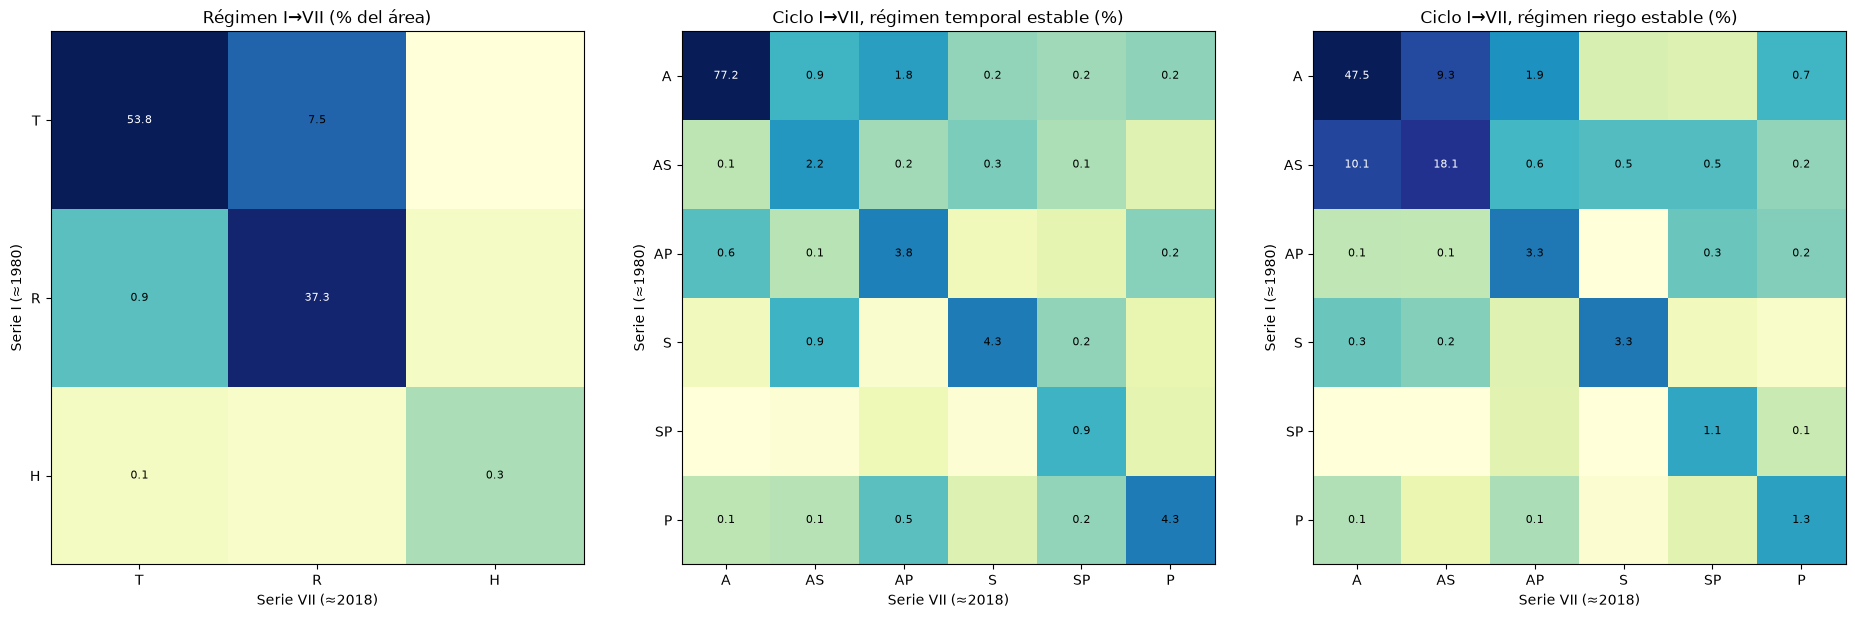

In [16]:
def matriz_transicion(df, ini, fin, orden):
    return (df.pivot_table(index=ini, columns=fin, values="area_km2", aggfunc="sum")
            .reindex(index=orden, columns=orden).fillna(0))


def dibujar_matriz(ax, m, titulo):
    pct = 100 * m / m.to_numpy().sum()
    ax.imshow(np.log10(pct.to_numpy() + 0.01), cmap="YlGnBu")
    for (i, j), v in np.ndenumerate(pct.to_numpy()):
        if v >= 0.05:
            ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8,
                    color="white" if v > 10 else "black")
    ax.set_xticks(range(len(m.columns)), m.columns)
    ax.set_yticks(range(len(m.index)), m.index)
    ax.set(xlabel="Serie VII (≈2018)", ylabel="Serie I (≈1980)", title=titulo)


fig, axes = plt.subplots(1, 3, figsize=(19, 6))
dibujar_matriz(axes[0], matriz_transicion(candidatos, "regimen_I", "regimen_VII", ["T", "R", "H"]),
               "Régimen I→VII (% del área)")
for ax, r in zip(axes[1:], ["T", "R"]):
    sub = candidatos[candidatos.n_cambios_regimen.eq(0) & candidatos.regimen_final.eq(r)]
    dibujar_matriz(ax, matriz_transicion(sub, "ciclo_I", "ciclo_VII", list(COLOR_CICLO)),
                   f"Ciclo I→VII, régimen {NOMBRE_REGIMEN[r].lower()} estable (%)")
plt.tight_layout()
plt.show()

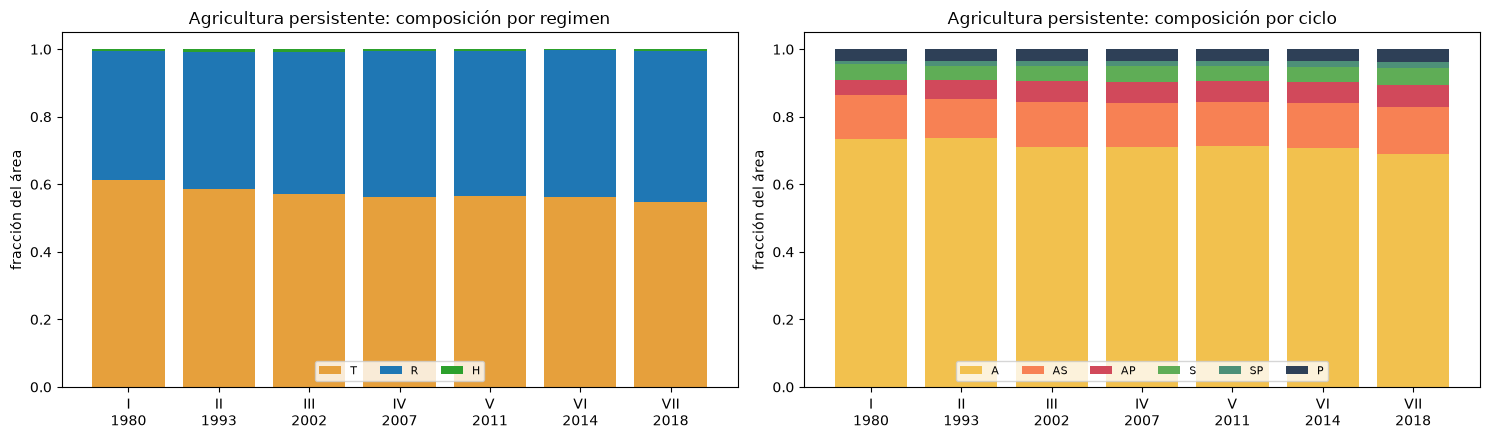

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (prefijo, colores) in zip(axes, [("regimen", COLOR_REGIMEN), ("ciclo", COLOR_CICLO)]):
    comp = pd.DataFrame({s: candidatos.groupby(f"{prefijo}_{s}").area_km2.sum() for s in SER}).T
    comp = comp.reindex(columns=list(colores)).fillna(0)
    comp = comp.div(comp.sum(axis=1), axis=0)
    abajo = np.zeros(len(SER))
    for c, color in colores.items():
        ax.bar([f"{s}\n{ANIO[s]}" for s in SER], comp[c], bottom=abajo, color=color, label=c)
        abajo += comp[c].to_numpy()
    ax.set(title=f"Agricultura persistente: composición por {prefijo}", ylabel="fracción del área")
    ax.legend(ncols=6, fontsize=8, loc="lower center")
plt.tight_layout()
plt.show()

In [18]:
# Trayectorias de clase más frecuentes por estado de trayectoria
cambiantes = candidatos[candidatos.estado_trayectoria.ne("estable")]
top_trayectorias = (
    cambiantes.groupby(["estado_trayectoria", "tipo_trayectoria", "trayectoria_clase"])["area_km2"]
    .sum().sort_values(ascending=False)
    .groupby(level="estado_trayectoria").head(6)
    .reset_index().sort_values(["estado_trayectoria", "area_km2"], ascending=[True, False])
)
top_trayectorias.round(1).reset_index(drop=True)

,estado_trayectoria,tipo_trayectoria,trayectoria_clase,area_km2
0,cambio_ambos,cambio_reciente,TA→TA→TA→TA→TA→TA→RS,740.0
1,cambio_ambos,cambio_sostenido,TA→RAS→RAS→RAS→RAS→RAS→RAS,282.0
2,cambio_ambos,cambio_sostenido,TA→TA→TA→RAS→RAS→RAS→RAS,201.0
3,cambio_ambos,cambio_sostenido,TA→RAP→RAP→RAP→RAP→RAP→RAP,160.0
4,cambio_ambos,cambio_sostenido,RAS→TA→TA→TA→TA→TA→TA,131.0
5,cambio_ambos,cambio_sostenido,TA→TA→RAS→RAS→RAS→RAS→RAS,130.0
6,cambio_ciclo,cambio_sostenido,RAS→RA→RA→RA→RA→RA→RA,2371.0
7,cambio_ciclo,cambio_sostenido,RA→RA→RAS→RAS→RAS→RAS→RAS,1858.0
8,cambio_ciclo,cambio_sostenido,RA→RAS→RAS→RAS→RAS→RAS→RAS,861.0
9,cambio_ciclo,cambio_sostenido,RAS→RAS→RAS→RA→RA→RA→RA,606.0


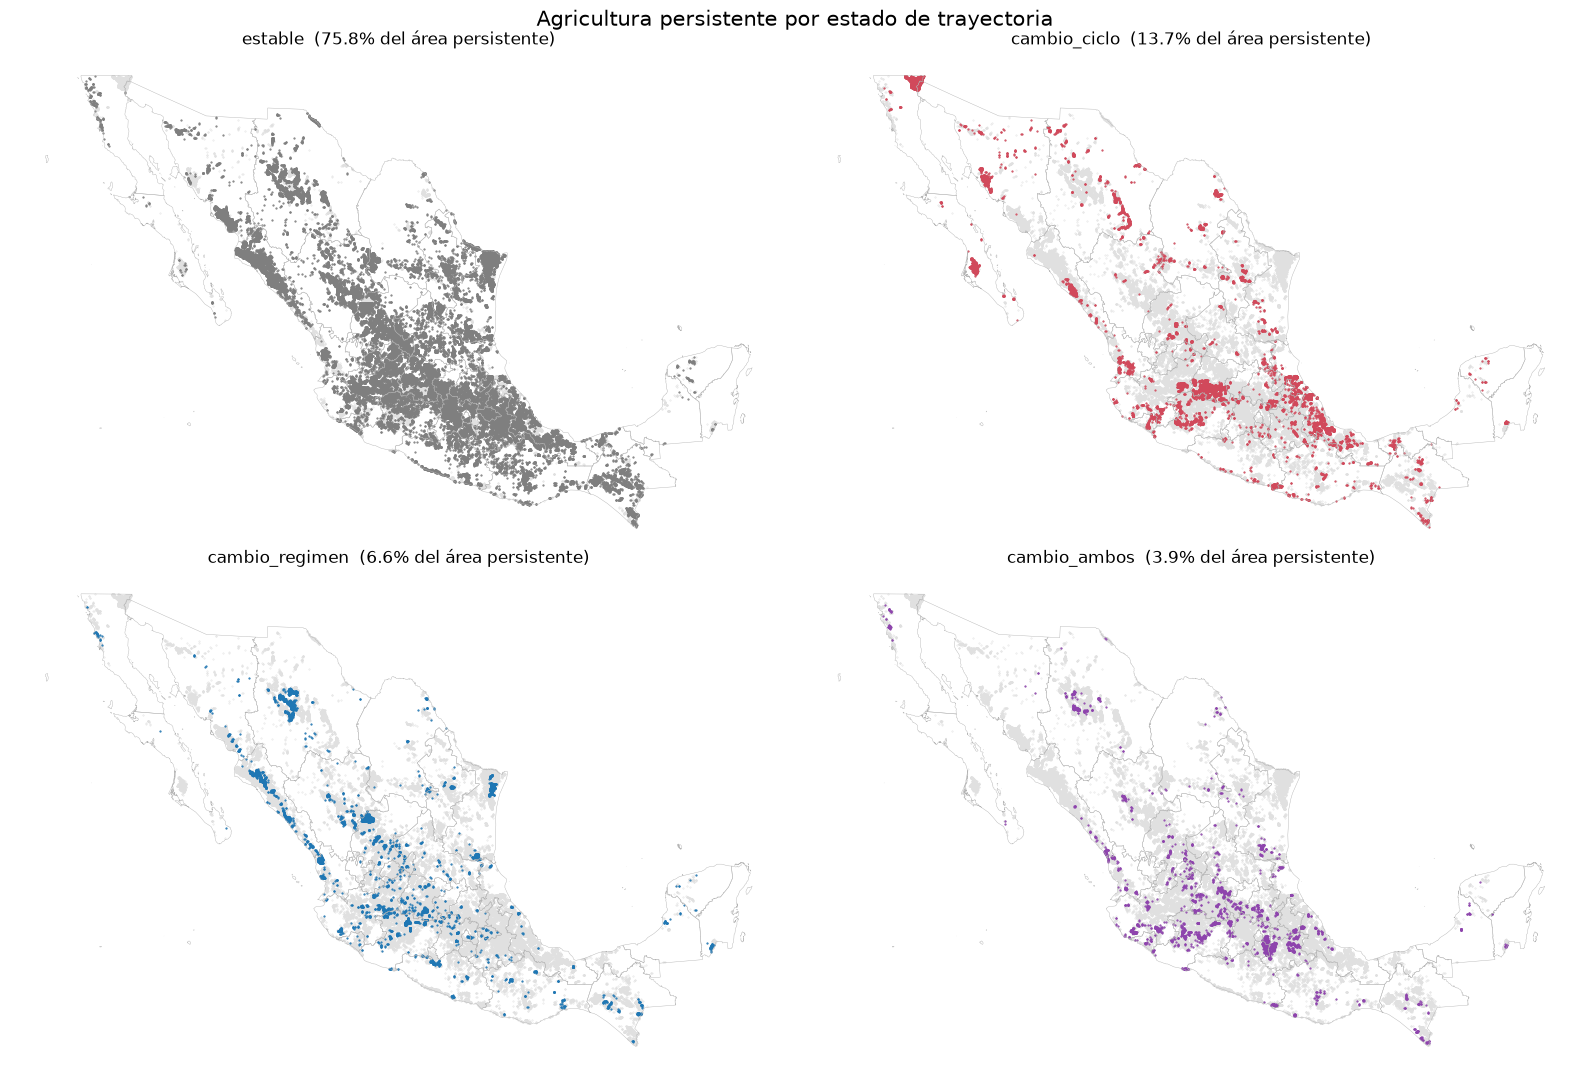

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
colores_estado = {"estable": "#7f7f7f", "cambio_ciclo": "#d1495b",
                  "cambio_regimen": "#1f77b4", "cambio_ambos": "#8e44ad"}
for ax, estado in zip(axes.flat, ORDEN_ESTADO):
    ENT_SIMPLE.boundary.plot(ax=ax, color="0.7", lw=0.3)
    ax.scatter(candidatos.x, candidatos.y, s=0.1, color="0.88", rasterized=True)
    sub = candidatos[candidatos.estado_trayectoria == estado]
    ax.scatter(sub.x, sub.y, s=0.3, color=colores_estado[estado], rasterized=True)
    pct = 100 * sub.area_km2.sum() / total_area
    ax.set_title(f"{estado}  ({pct:.1f}% del área persistente)")
    ax.set_axis_off()
plt.suptitle("Agricultura persistente por estado de trayectoria", fontsize=15)
plt.tight_layout()
plt.show()

## 7. Contexto municipal y producción SIAP

- **Municipio.** A cada candidato se le asignan su municipio y su entidad con
  `00mun.shp` (Marco Geoestadístico 2025).
- **SIAP 2003–2025** (`data/process/DGSIAP`). Por municipio se calculan los promedios
  anuales de superficie sembrada por modalidad (Riego/Temporal) y por grupo de ciclo
  (anuales = PV + OI; perennes) y el valor de la producción (2021–2025, pesos corrientes).
- **Correspondencias INEGI ↔ SIAP.** R ↔ Riego; T y H ↔ Temporal (el SIAP no distingue
  la humedad). Se usa el **régimen final** (Serie VII).
- **Consistencia.** Se descartan los candidatos de municipios que no reportan superficie
  sembrada en su modalidad. Los municipios sin registro en el SIAP (de creación reciente)
  se conservan con peso neutro.
- **Peso de muestreo.** Es la raíz de la densidad de siembra municipal en la modalidad
  (ha sembradas por km² agrícola de la Serie VII en esa modalidad), recortada a los
  percentiles 1–99 y normalizada a mediana 1. El peso se duplica si el punto está a
  `≥ DIST_PREF` del borde.
- **Coherencia de los cambios.** Para los cambios ocurridos después de la Serie III
  (año ≥ 2007), se compara la dirección del cambio con la tendencia municipal entre
  2003–2005 y 2016–2018: la participación del riego para los cambios de régimen y la de
  los perennes para los de ciclo.

In [20]:
MUN = gpd.read_file(MARCO / "00mun.shp").to_crs(CRS_TRABAJO)
NOM_ENT = ENT.set_index("CVE_ENT")["NOMGEO"]
COLS_MUN = ["CVEGEO", "CVE_ENT", "NOMGEO"]


def asignar_municipio(pts):
    j = gpd.sjoin(pts[["geometry"]], MUN[COLS_MUN + ["geometry"]], how="left", predicate="within")
    j = j[~j.index.duplicated(keep="first")].reindex(pts.index)[COLS_MUN]
    faltan = j["CVEGEO"].isna()
    if faltan.any():
        cerca = gpd.sjoin_nearest(pts.loc[faltan, ["geometry"]], MUN[COLS_MUN + ["geometry"]], how="left")
        j.loc[faltan, COLS_MUN] = cerca[~cerca.index.duplicated(keep="first")][COLS_MUN]
    return j.rename(columns={"NOMGEO": "NOM_MUN"})


archivos = sorted(SIAP_DIR.glob("ProdAgro_*_mun.csv"))
siap = pd.concat([pd.read_csv(f, index_col=0, low_memory=False) for f in archivos], ignore_index=True)
siap["CVEGEO"] = siap["Idestado"].map("{:02d}".format) + siap["Idmunicipio"].map("{:03d}".format)
siap["grupo_ciclo"] = np.where(siap["Nomcicloproductivo"].eq("Perennes"), "perennes_ha", "anuales_ha")
por_anio = pd.concat([
    siap.pivot_table(index=["CVEGEO", "Anio"], columns="Nommodalidad", values="Sembrada",
                     aggfunc="sum", fill_value=0).rename(columns={"Riego": "riego_ha", "Temporal": "temporal_ha"}),
    siap.pivot_table(index=["CVEGEO", "Anio"], columns="grupo_ciclo", values="Sembrada",
                     aggfunc="sum", fill_value=0),
    siap.groupby(["CVEGEO", "Anio"])["Valorproduccion"].sum().rename("valor_mxn"),
], axis=1).reset_index()
por_anio["part_riego"] = por_anio.riego_ha / (por_anio.riego_ha + por_anio.temporal_ha)
por_anio["part_perennes"] = por_anio.perennes_ha / (por_anio.perennes_ha + por_anio.anuales_ha)

mun_siap = por_anio.groupby("CVEGEO")[["riego_ha", "temporal_ha", "perennes_ha", "anuales_ha"]].mean()
mun_siap["sembrada_ha"] = mun_siap.riego_ha + mun_siap.temporal_ha
mun_siap["valor_mxn_2021_2025"] = por_anio[por_anio.Anio.between(2021, 2025)].groupby("CVEGEO").valor_mxn.mean()
inicio = por_anio[por_anio.Anio.between(2003, 2005)].groupby("CVEGEO")[["part_riego", "part_perennes"]].mean()
final = por_anio[por_anio.Anio.between(2016, 2018)].groupby("CVEGEO")[["part_riego", "part_perennes"]].mean()
mun_siap["delta_part_riego"] = final.part_riego - inicio.part_riego
mun_siap["delta_part_perennes"] = final.part_perennes - inicio.part_perennes
print(f"SIAP: {siap.Anio.min()}–{siap.Anio.max()}, {len(siap):,} registros, {len(mun_siap):,} municipios")
mun_siap.describe().T.round(2)

SIAP: 2003–2025, 825,089 registros, 2,452 municipios


,count,mean,std,min,25%,50%,75%,max
riego_ha,2452.0,2.328210e+03,9.096890e+03,0.00,5.43,173.72,1.357290e+03,1.849899e+05
temporal_ha,2452.0,6.320000e+03,1.170228e+04,0.00,798.67,2614.49,7.148350e+03,2.162544e+05
perennes_ha,2452.0,2.525820e+03,6.721590e+03,0.00,59.82,448.88,2.193850e+03,1.888537e+05
anuales_ha,2452.0,6.122390e+03,1.383276e+04,0.00,732.34,2166.42,5.869560e+03,2.152174e+05
sembrada_ha,2452.0,8.648220e+03,1.607885e+04,5.64,1179.95,3547.08,9.829040e+03,2.162544e+05
valor_mxn_2021_2025,2446.0,3.409438e+08,8.580740e+08,62542.80,12985176.51,64020327.44,2.935937e+08,1.214830e+10
delta_part_riego,2417.0,1.000000e-02,1.000000e-01,-0.49,-0.00,0.00,3.000000e-02,1.000000e+00
delta_part_perennes,2417.0,4.000000e-02,1.100000e-01,-0.98,-0.01,0.01,6.000000e-02,7.600000e-01


In [21]:
# Superficie agrícola de la Serie VII por municipio y modalidad (malla base de 1 km)
base_mun = asignar_municipio(base)
area_agri = (pd.DataFrame({"CVEGEO": base_mun.CVEGEO.to_numpy(),
                           "modalidad": np.where(base.clase_VII.str[0].eq("R"), "Riego", "Temporal"),
                           "area_km2": base.area_km2.to_numpy()})
             .pivot_table(index="CVEGEO", columns="modalidad", values="area_km2", aggfunc="sum", fill_value=0))

cand = candidatos.join(asignar_municipio(candidatos))
cand["NOM_ENT"] = cand.CVE_ENT.map(NOM_ENT)
cand["modalidad_siap"] = np.where(cand.regimen_final.eq("R"), "Riego", "Temporal")
ms = mun_siap.reindex(cand.CVEGEO)
es_riego = cand.modalidad_siap.eq("Riego").to_numpy()
sembrada_mod = np.where(es_riego, ms.riego_ha, ms.temporal_ha)
aa = area_agri.reindex(cand.CVEGEO).fillna(0)
area_mod = np.maximum(np.where(es_riego, aa["Riego"], aa["Temporal"]), 1.0)
cand["siap_sembrada_mod_ha"] = sembrada_mod
cand["siap_sembrada_ha"] = ms.sembrada_ha.to_numpy()
cand["siap_valor_mxn"] = ms.valor_mxn_2021_2025.to_numpy()
cand["siap_densidad_ha_km2"] = sembrada_mod / area_mod
cand["delta_part_riego"] = ms.delta_part_riego.to_numpy()
cand["delta_part_perennes"] = ms.delta_part_perennes.to_numpy()
cand["consistente_siap"] = pd.array(
    [pd.NA if np.isnan(v) else bool(v > 0) for v in sembrada_mod], dtype="boolean")

densidad = cand.siap_densidad_ha_km2.where(cand.siap_densidad_ha_km2 > 0)
p01, p99 = densidad.quantile([0.01, 0.99])
peso = np.sqrt(densidad.clip(p01, p99))
cand["peso_siap"] = (peso / peso.median()).fillna(1.0)
cand["peso_muestreo"] = cand.peso_siap * np.where(cand.dist_borde_min_m >= DIST_PREF, 2.0, 1.0)


def coherencia(direccion, delta, anio_cambio, positivos, negativos):
    res = pd.Series(pd.NA, index=direccion.index, dtype="boolean")
    evaluable = anio_cambio.ge(2007).fillna(False).astype(bool) & delta.notna()
    pos = evaluable & direccion.isin(positivos)
    neg = evaluable & direccion.isin(negativos)
    res[pos] = delta[pos] > 0
    res[neg] = delta[neg] < 0
    return res


cand["coherente_siap_regimen"] = coherencia(cand.direccion_regimen, cand.delta_part_riego,
                                            cand.anio_ultimo_cambio_regimen, ["T→R", "H→R"], ["R→T", "R→H"])
cand["coherente_siap_ciclo"] = coherencia(cand.direccion_ciclo, cand.delta_part_perennes,
                                          cand.anio_ultimo_cambio_ciclo, ["hacia_perenne"], ["hacia_anual"])
ambos_na = cand.coherente_siap_regimen.isna() & cand.coherente_siap_ciclo.isna()
cand["cambio_coherente_siap"] = (cand.coherente_siap_regimen.fillna(True)
                                 & cand.coherente_siap_ciclo.fillna(True)).astype("boolean")
cand.loc[ambos_na, "cambio_coherente_siap"] = pd.NA

POBLACION = cand[cand.consistente_siap.fillna(True).astype(bool)].reset_index(drop=True)
print(f"Candidatos: {len(cand):,} | descartados por inconsistencia con el SIAP: "
      f"{(~cand.consistente_siap.fillna(True).astype(bool)).sum():,} | población final: {len(POBLACION):,}")
print("Municipios sin registro en el SIAP (peso neutro):", cand.loc[cand.consistente_siap.isna(), "CVEGEO"].nunique())
(cand.groupby("estado_trayectoria")["cambio_coherente_siap"]
 .agg(evaluables="count", coherentes="sum").reindex(ORDEN_ESTADO)
 .assign(pct_coherente=lambda d: (100 * d.coherentes / d.evaluables).round(1)))

Candidatos: 98,031 | descartados por inconsistencia con el SIAP: 213 | población final: 97,818
Municipios sin registro en el SIAP (peso neutro): 8


,evaluables,coherentes,pct_coherente
estado_trayectoria,,,
estable,0,0,<NA>
cambio_ciclo,2908,2145,73.8
cambio_regimen,1854,1483,80.0
cambio_ambos,1992,942,47.3


In [22]:
# Agricultura persistente por entidad federativa
por_estado = (POBLACION.pivot_table(index="NOM_ENT", columns="estado_trayectoria", values="area_km2",
                                    aggfunc="sum", fill_value=0).reindex(columns=ORDEN_ESTADO).fillna(0))
por_estado["area_total_km2"] = por_estado.sum(axis=1)
por_estado["%_con_cambio"] = 100 * (1 - por_estado["estable"] / por_estado["area_total_km2"])
por_estado["candidatos"] = POBLACION.groupby("NOM_ENT").size()
por_estado.sort_values("area_total_km2", ascending=False).round(1)

estado_trayectoria,estable,cambio_ciclo,cambio_regimen,cambio_ambos,area_total_km2,%_con_cambio,candidatos
NOM_ENT,,,,,,,
Sinaloa,7170.0,571.0,800.0,109.0,8650.0,17.1,8650
Tamaulipas,7510.4,117.0,811.1,104.0,8542.5,12.1,8580
Zacatecas,5529.0,248.0,864.0,122.0,6763.0,18.2,6763
Guanajuato,3180.9,2602.0,244.2,251.7,6278.9,49.3,6427
Veracruz de Ignacio de la Llave,4393.8,1667.9,56.9,123.4,6242.1,29.6,7668
Jalisco,4515.2,468.6,265.6,269.4,5518.9,18.2,7527
Chihuahua,3310.0,560.0,1122.0,238.0,5230.0,36.7,5230
Puebla,4114.0,341.0,25.0,492.0,4972.0,17.3,4972
Sonora,3669.0,724.0,46.0,4.0,4443.0,17.4,4443


## 8. Diseño muestral

**Estratos (estratificación conjunta):**

- **Estables:** un estrato por clase (`estable|TA`, `estable|RAS`, …), hasta 18.
- **Con cambio:** se combinan el estado de trayectoria, la dirección y el tipo:
  - `cambio_ciclo|{direccion_ciclo}|{tipo_tray_ciclo}`, p. ej. `cambio_ciclo|hacia_perenne|cambio_sostenido`;
  - `cambio_regimen|{direccion_regimen}|{tipo_tray_regimen}`, p. ej. `cambio_regimen|T→R|cambio_reciente`;
  - `cambio_ambos|{direccion_regimen}|{tipo_trayectoria}`.

  Los estratos de cambio con menos de `MIN_CAND_ESTRATO` candidatos se agrupan en
  `{estado}|otros`.

**Asignación.** Cada estrato recibe `n_h = max(mínimo, N · A_h^ALFA / Σ A^ALFA)` puntos,
donde `A_h` es su área. Con `ALFA = 0.5` (raíz cuadrada) se equilibra la
proporcionalidad al área con la presencia de las clases y trayectorias raras. El tope
es el número de candidatos del estrato.

**Selección espacialmente balanceada (tipo GRTS).**

1. Los candidatos de cada estrato se ordenan sobre una curva de Morton (Z) con origen
   aleatorio y una permutación aleatoria de cuadrantes en cada nivel.
2. Sobre ese orden se hace un muestreo sistemático con probabilidad proporcional a
   `peso_muestreo`.

Así los puntos quedan repartidos en el territorio y se favorecen los municipios
productivos y los puntos alejados del borde.

**Cobertura garantizada.** Si alguna de las 18 clases no aparece como `clase_final`, o
algún estado con candidatos queda sin punto, se agrega su mejor candidato. Se prefieren
los estables, luego el mayor peso y luego la mayor distancia al borde, y la columna
`respaldo` lo indica.

**Estimación.** Cada punto guarda su `prob_inclusion` y su `factor_expansion_km2`
(área / probabilidad), que permiten estimaciones de Horvitz-Thompson de superficie.

In [23]:
def asignar_estrato(df):
    est = df["estado_trayectoria"]
    estrato = pd.Series(np.select(
        [est.eq("estable"), est.eq("cambio_ciclo"), est.eq("cambio_regimen")],
        ["estable|" + df["clase_final"],
         "cambio_ciclo|" + df["direccion_ciclo"] + "|" + df["tipo_tray_ciclo"],
         "cambio_regimen|" + df["direccion_regimen"] + "|" + df["tipo_tray_regimen"]],
        "cambio_ambos|" + df["direccion_regimen"] + "|" + df["tipo_trayectoria"],
    ), index=df.index)
    conteo = estrato.map(estrato.value_counts())
    chicos = est.ne("estable") & conteo.lt(MIN_CAND_ESTRATO)
    estrato[chicos] = est[chicos] + "|otros"
    return estrato


POBLACION["estrato"] = asignar_estrato(POBLACION)
TABLA_ESTRATOS = (POBLACION.groupby("estrato")
                  .agg(candidatos=("area_km2", "size"), area_km2=("area_km2", "sum")))
TABLA_ESTRATOS["estable"] = TABLA_ESTRATOS.index.str.startswith("estable|")
ESTRATOS = POBLACION.groupby("estrato").indices
X, Y = POBLACION["x"].to_numpy(), POBLACION["y"].to_numpy()
PESO = POBLACION["peso_muestreo"].to_numpy()
print(f"Estratos: {len(TABLA_ESTRATOS)} ({TABLA_ESTRATOS.estable.sum()} estables, "
      f"{(~TABLA_ESTRATOS.estable).sum()} de cambio)")
TABLA_ESTRATOS.sort_values("area_km2", ascending=False).round(1)

Estratos: 44 (18 estables, 26 de cambio)


,candidatos,area_km2,estable
estrato,,,
estable|TA,37412,37412.0,True
estable|RA,16198,16198.0,True
estable|RAS,6038,6038.0,True
cambio_ciclo|hacia_perenne|cambio_sostenido,6096,5779.1,False
cambio_ciclo|hacia_anual|cambio_sostenido,4974,4901.8,False
cambio_regimen|T→R|cambio_sostenido,3800,3800.0,False
estable|TP,2070,2070.0,True
estable|TS,2044,2044.0,True
estable|TAP,1822,1822.0,True


In [24]:
def asignacion(n_objetivo):
    raiz = TABLA_ESTRATOS["area_km2"] ** ALFA
    n = np.round(n_objetivo * raiz / raiz.sum())
    minimo = np.where(TABLA_ESTRATOS["estable"], N_MIN_ESTABLE, N_MIN_CAMBIO)
    return pd.Series(
        np.minimum(np.maximum(n, minimo), TABLA_ESTRATOS["candidatos"]).astype(int),
        index=TABLA_ESTRATOS.index, name="n_asignado",
    )


def probabilidades(w, n):
    # Probabilidades de inclusión ∝ w con suma n, acotadas a 1
    pi = np.zeros(len(w))
    fijos = np.zeros(len(w), dtype=bool)
    while True:
        resto = n - fijos.sum()
        pi[~fijos] = resto * w[~fijos] / w[~fijos].sum()
        nuevos = (pi > 1) & ~fijos
        if not nuevos.any():
            return np.minimum(pi, 1.0)
        fijos |= nuevos
        pi[fijos] = 1.0


def orden_grts(x, y, rng, niveles=16):
    # Orden de Morton con origen aleatorio y permutación aleatoria de cuadrantes por nivel
    lado = 2 * max(np.ptp(x), np.ptp(y), 1.0)
    sx, sy = rng.uniform(0, lado / 2, size=2)
    escala = (2**niveles - 1) / lado
    ix = ((x - x.min() + sx) * escala).astype(np.uint64)
    iy = ((y - y.min() + sy) * escala).astype(np.uint64)
    codigo = np.zeros(len(x), dtype=np.uint64)
    uno = np.uint64(1)
    for b in range(niveles - 1, -1, -1):
        bit = np.uint64(b)
        digito = ((((iy >> bit) & uno) << uno) | ((ix >> bit) & uno)).astype(np.intp)
        permutacion = rng.permutation(4).astype(np.uint64)
        codigo = (codigo << np.uint64(2)) | permutacion[digito]
    return np.argsort(codigo, kind="stable")


def seleccion_sistematica(pi_ordenado, rng):
    acumulado = np.cumsum(pi_ordenado)
    marcas = rng.uniform(0, 1) + np.arange(int(round(acumulado[-1])))
    return np.unique(np.minimum(np.searchsorted(acumulado, marcas, side="right"), len(acumulado) - 1))


ESTADOS_POB = sorted(POBLACION["CVE_ENT"].unique())
CLASES_POB = [c for c in CLASES if c in set(POBLACION["clase_final"])]


def muestrear(n_objetivo, seed):
    rng = np.random.default_rng(seed)
    n_h = asignacion(n_objetivo)
    pi_pob = np.zeros(len(POBLACION))
    elegidos = []
    for estrato, idx in ESTRATOS.items():
        pi = probabilidades(PESO[idx], n_h[estrato])
        pi_pob[idx] = pi
        orden = orden_grts(X[idx], Y[idx], rng)
        elegidos.append(idx[orden[seleccion_sistematica(pi[orden], rng)]])
    elegidos = np.concatenate(elegidos)
    muestra = POBLACION.iloc[elegidos].copy()
    muestra["prob_inclusion"] = pi_pob[elegidos]
    muestra["respaldo"] = ""
    for columna, valores, etiqueta in [("clase_final", CLASES_POB, "clase"), ("CVE_ENT", ESTADOS_POB, "estado")]:
        for valor in sorted(set(valores) - set(muestra[columna])):
            opciones = POBLACION[POBLACION[columna].eq(valor) & ~POBLACION.index.isin(muestra.index)]
            mejor = opciones.assign(_estable=opciones.estado_trayectoria.eq("estable")).sort_values(
                ["_estable", "peso_muestreo", "dist_borde_min_m"], ascending=False).index[0]
            extra = POBLACION.loc[[mejor]].assign(prob_inclusion=pi_pob[mejor], respaldo=etiqueta)
            muestra = pd.concat([muestra, extra])
    muestra["factor_expansion_km2"] = muestra["area_km2"] / muestra["prob_inclusion"]
    return muestra


prueba = muestrear(1000, SEED)
print(f"n = {len(prueba)}, clases finales = {prueba.clase_final.nunique()}/{len(CLASES_POB)}, "
      f"estados = {prueba.CVE_ENT.nunique()}/{len(ESTADOS_POB)}, respaldos = {prueba.respaldo.ne('').sum()}")
print("Área estimada (HT) vs. real (km²):", round(prueba.factor_expansion_km2.sum()), "vs",
      round(POBLACION.area_km2.sum()))

n = 1002, clases finales = 18/18, estados = 32/32, respaldos = 0
Área estimada (HT) vs. real (km²): 94130 vs 92531


## 9. Curva de representatividad: ¿cuántos puntos hacen falta?

Para cada tamaño objetivo N se extraen `SEMILLAS` muestras y se mide qué tan bien
reproducen la población de agricultura persistente:

| Métrica | Qué mide | Umbral |
|---|---|---|
| clases, estados, estados de trayectoria cubiertos | presencia de todos los tipos y de todo el país | todos (mínimo entre semillas) |
| `tvd_clase`, `tvd_estado`, `tvd_trayectoria` | distancia de variación total entre la distribución de superficie estimada por Horvitz-Thompson y la real (0 = idéntica) | ≤ `UMBRALES` |
| `err_regimen` | error relativo máximo de la superficie estimada de Riego y Temporal | ≤ `UMBRALES` |
| `p95_dist_km` | percentil 95 de la distancia de la agricultura persistente al punto más cercano | ≤ `UMBRALES` |
| `cobertura_siap` | fracción de la superficie sembrada nacional (SIAP) en municipios con al menos un punto | ≥ `UMBRALES` |

**N\*** es el menor N a partir del cual se cumplen todos los umbrales, en promedio entre
semillas, para ese N y todos los mayores.

In [25]:
AREA_POB = {c: POBLACION.groupby(c)["area_km2"].sum() / POBLACION["area_km2"].sum()
            for c in ("clase_final", "CVE_ENT", "estado_trayectoria")}
AREA_REGIMEN = POBLACION.groupby("regimen_final")["area_km2"].sum()
EVAL_GEOM = POBLACION.sample(30000, weights="area_km2", random_state=SEED).geometry.to_numpy()
SEMBRADA_NAC = mun_siap["sembrada_ha"].sum()
VALOR_NAC = mun_siap["valor_mxn_2021_2025"].sum()


def tvd(muestra, columna):
    est = muestra.groupby(columna)["factor_expansion_km2"].sum()
    real = AREA_POB[columna]
    est = (est / est.sum()).reindex(real.index, fill_value=0)
    return 0.5 * (est - real).abs().sum()


def metricas(muestra):
    est_reg = muestra.groupby("regimen_final")["factor_expansion_km2"].sum()
    _, dist = shapely.STRtree(muestra.geometry.to_numpy()).query_nearest(
        EVAL_GEOM, return_distance=True, all_matches=False)
    municipios = muestra["CVEGEO"].unique()
    return {
        "n": len(muestra),
        "clases": muestra["clase_final"].nunique(),
        "estados": muestra["CVE_ENT"].nunique(),
        "estados_trayectoria": muestra["estado_trayectoria"].nunique(),
        "tvd_clase": tvd(muestra, "clase_final"),
        "tvd_estado": tvd(muestra, "CVE_ENT"),
        "tvd_trayectoria": tvd(muestra, "estado_trayectoria"),
        "err_regimen": max(abs(est_reg.get(r, 0) - AREA_REGIMEN[r]) / AREA_REGIMEN[r] for r in ("T", "R")),
        "p95_dist_km": np.percentile(dist, 95) / 1000,
        "cobertura_siap": mun_siap["sembrada_ha"].reindex(municipios).sum() / SEMBRADA_NAC,
        "cobertura_valor": mun_siap["valor_mxn_2021_2025"].reindex(municipios).sum() / VALOR_NAC,
    }


curva = pd.DataFrame([
    {"n_objetivo": n, "semilla": k, **metricas(muestrear(n, SEED + k))}
    for n in N_GRID for k in range(SEMILLAS)
])
resumen_curva = curva.groupby("n_objetivo").agg(
    n=("n", "mean"), clases=("clases", "min"), estados=("estados", "min"),
    estados_trayectoria=("estados_trayectoria", "min"),
    tvd_clase=("tvd_clase", "mean"), tvd_estado=("tvd_estado", "mean"),
    tvd_trayectoria=("tvd_trayectoria", "mean"), err_regimen=("err_regimen", "mean"),
    p95_dist_km=("p95_dist_km", "mean"), cobertura_siap=("cobertura_siap", "mean"),
    cobertura_valor=("cobertura_valor", "mean"),
)
criterios = pd.DataFrame({
    "clases": resumen_curva.clases >= len(CLASES_POB),
    "estados": resumen_curva.estados >= len(ESTADOS_POB),
    "trayectorias": resumen_curva.estados_trayectoria >= POBLACION.estado_trayectoria.nunique(),
    **{m: resumen_curva[m] <= UMBRALES[m] for m in
       ("tvd_clase", "tvd_estado", "tvd_trayectoria", "err_regimen", "p95_dist_km")},
    "cobertura_siap": resumen_curva.cobertura_siap >= UMBRALES["cobertura_siap"],
})
resumen_curva["cumple"] = criterios.all(axis=1)
# Debe cumplirse para ese N y todos los mayores
estable_desde = resumen_curva["cumple"][::-1].cummin()[::-1]
if estable_desde.any():
    N_ESTRELLA = int(estable_desde.idxmax())
else:
    N_ESTRELLA = N_GRID[-1]
    print("Ningún N de la malla cumple todos los umbrales; se usa el máximo.")
print(f"N* = {N_ESTRELLA}")
resumen_curva.round(3)

N* = 1000


,n,clases,estados,estados_trayectoria,tvd_clase,tvd_estado,tvd_trayectoria,err_regimen,p95_dist_km,cobertura_siap,cobertura_valor,cumple
n_objetivo,,,,,,,,,,,,
100,133.6,18,32,4,0.047,0.201,0.020,0.109,129.605,0.183,0.216,False
200,218.6,18,32,4,0.037,0.134,0.011,0.060,94.534,0.258,0.317,False
300,316.6,18,32,4,0.040,0.110,0.013,0.058,73.824,0.323,0.384,False
500,507.6,18,32,4,0.025,0.078,0.010,0.050,59.341,0.410,0.483,False
750,753.8,18,32,4,0.023,0.063,0.009,0.031,48.426,0.473,0.569,False
1000,1002.2,18,32,4,0.015,0.046,0.005,0.028,41.358,0.515,0.615,True
1500,1503.2,18,32,4,0.011,0.045,0.005,0.018,32.399,0.590,0.697,True
2000,2001.0,18,32,4,0.012,0.035,0.003,0.014,28.180,0.630,0.737,True
3000,2999.2,18,32,4,0.011,0.028,0.003,0.021,22.548,0.688,0.792,True


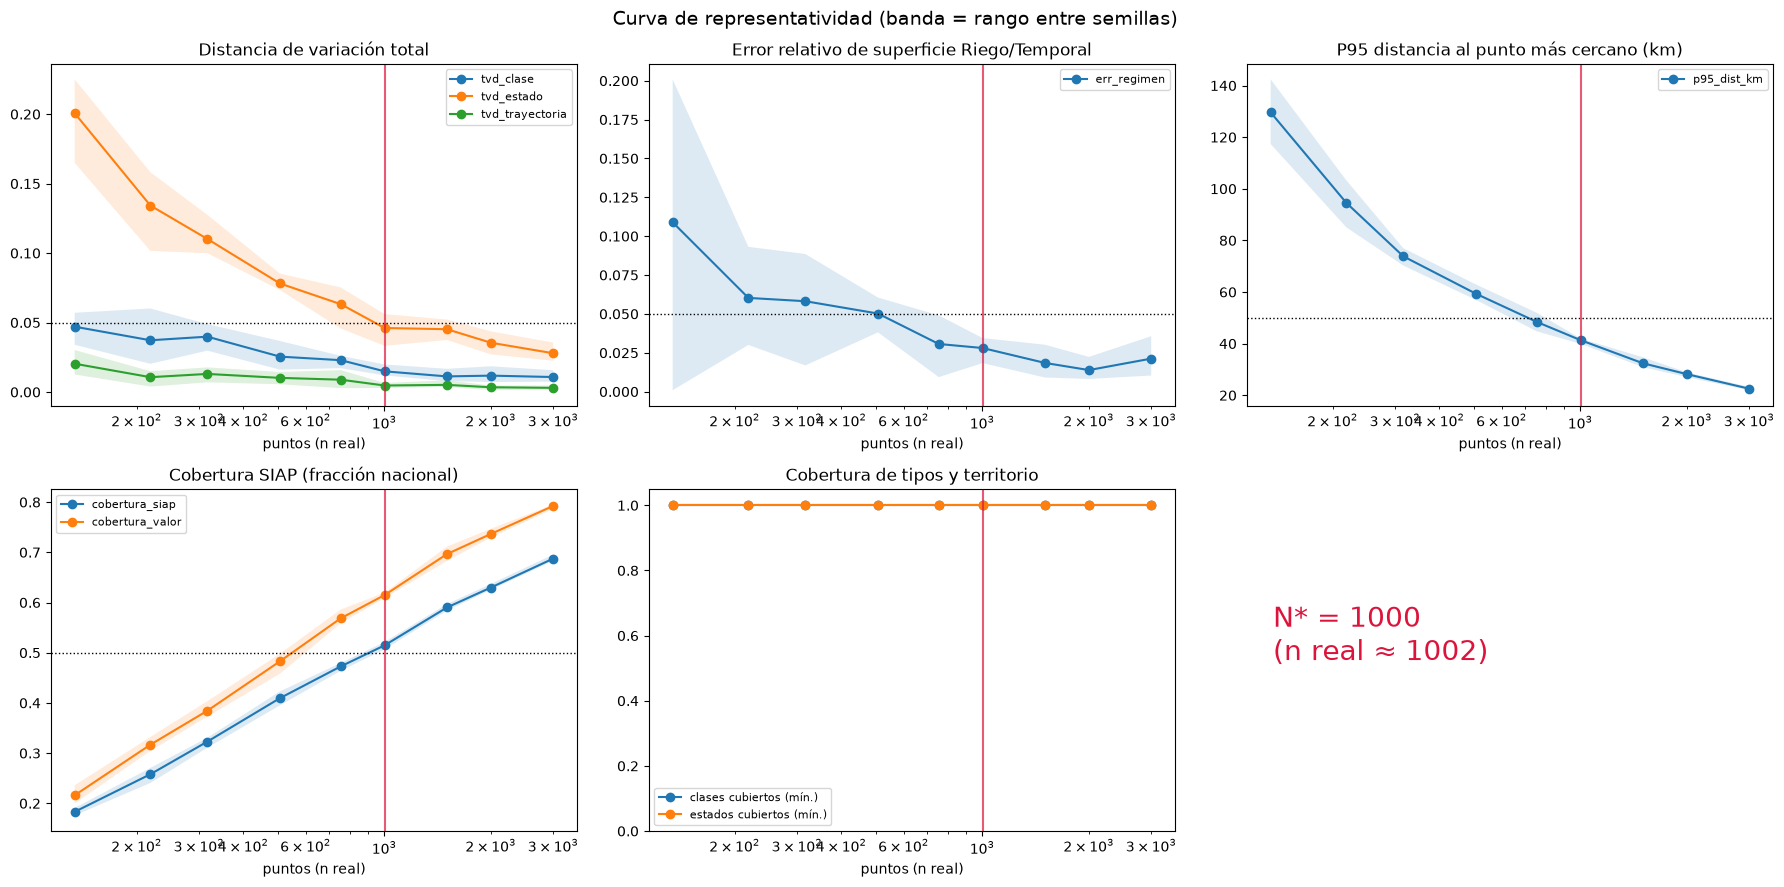

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
ejes = resumen_curva["n"]
paneles = [
    (["tvd_clase", "tvd_estado", "tvd_trayectoria"], "Distancia de variación total", UMBRALES["tvd_clase"]),
    (["err_regimen"], "Error relativo de superficie Riego/Temporal", UMBRALES["err_regimen"]),
    (["p95_dist_km"], "P95 distancia al punto más cercano (km)", UMBRALES["p95_dist_km"]),
    (["cobertura_siap", "cobertura_valor"], "Cobertura SIAP (fracción nacional)", UMBRALES["cobertura_siap"]),
]
for ax, (cols_m, titulo, umbral) in zip(axes.flat, paneles):
    for c in cols_m:
        ax.plot(ejes, resumen_curva[c], marker="o", label=c)
        disp = curva.groupby("n_objetivo")[c]
        ax.fill_between(ejes, disp.min(), disp.max(), alpha=0.15)
    ax.axhline(umbral, color="k", ls=":", lw=1)
    ax.set(title=titulo, xscale="log", xlabel="puntos (n real)")
    ax.legend(fontsize=8)
ax = axes.flat[4]
for c, total in [("clases", len(CLASES_POB)), ("estados", len(ESTADOS_POB))]:
    ax.plot(ejes, resumen_curva[c] / total, marker="o", label=f"{c} cubiertos (mín.)")
ax.set(title="Cobertura de tipos y territorio", xscale="log", ylim=(0, 1.05), xlabel="puntos (n real)")
ax.legend(fontsize=8)
for ax in axes.flat[:5]:
    ax.axvline(resumen_curva.loc[N_ESTRELLA, "n"], color="crimson", lw=1.5, alpha=0.7)
axes.flat[5].set_axis_off()
axes.flat[5].text(0.05, 0.5, f"N* = {N_ESTRELLA}\n(n real ≈ {resumen_curva.loc[N_ESTRELLA, 'n']:.0f})",
                  fontsize=20, color="crimson")
plt.suptitle("Curva de representatividad (banda = rango entre semillas)", fontsize=14)
plt.tight_layout()
plt.show()

## 10. Muestra final

In [27]:
muestra = muestrear(N_ESTRELLA, SEED)
orden_clase = {c: i for i, c in enumerate(CLASES)}
orden_estado = {e: i for i, e in enumerate(ORDEN_ESTADO)}
muestra = muestra.sort_values(
    by=["clase_final", "estado_trayectoria", "CVEGEO"],
    key=lambda s: s.map(orden_clase) if s.name == "clase_final"
    else s.map(orden_estado) if s.name == "estado_trayectoria" else s,
).reset_index(drop=True)
muestra.insert(0, "id_punto", [f"AGP{i + 1:04d}" for i in range(len(muestra))])
geo = muestra.to_crs(CRS_SALIDA).geometry
muestra["lon"], muestra["lat"] = geo.x.round(6), geo.y.round(6)
muestra["descripcion"] = muestra["clase_final"].map(DESCRIPCION)
print(f"Puntos: {len(muestra)} | clases finales: {muestra.clase_final.nunique()} | "
      f"estados: {muestra.CVE_ENT.nunique()} | municipios: {muestra.CVEGEO.nunique()} | "
      f"respaldos: {muestra.respaldo.ne('').sum()}")
muestra.groupby(["estado_trayectoria", "tipo_trayectoria"]).size().unstack(fill_value=0).reindex(ORDEN_ESTADO)

Puntos: 1002 | clases finales: 18 | estados: 32 | municipios: 490 | respaldos: 0


tipo_trayectoria,cambio_reciente,cambio_sostenido,estable,oscilante
estado_trayectoria,,,,
estable,0,0,576,0
cambio_ciclo,35,135,0,17
cambio_regimen,13,85,0,35
cambio_ambos,26,50,0,30


### Verificación independiente

Se vuelven a leer los 7 shapefiles originales, sin usar los cachés, y se repite para los
puntos finales el cruce espacial, la distancia al borde y el cálculo del seguimiento.
Todo debe coincidir.

In [28]:
verif = muestra[["id_punto", "geometry"]].copy()
for s in SER:
    fresco = CARGADORES[SERIES[s]["esquema"]](s, SERIES[s])
    j = gpd.sjoin(verif[["geometry"]], fresco[["clase", "geometry"]], how="left", predicate="within")
    j = j[~j.index.duplicated(keep="first")].reindex(verif.index)
    verif[f"clase_{s}"] = j["clase"]
    poligonos = fresco.geometry.to_numpy()[j["index_right"].to_numpy().astype(int)]
    verif[f"dist_{s}"] = shapely.distance(verif.geometry.to_numpy(), shapely.boundary(poligonos))
    del fresco

verif = agregar_seguimiento(verif)
assert verif[COLS_CLASE].notna().all().all(), "hay puntos no agrícolas en alguna serie"
assert (verif[[f"dist_{s}" for s in SER]] >= DIST_MIN - 1e-6).all().all(), "puntos a menos de DIST_MIN del borde"
for col in COLS_CLASE + ["trayectoria_clase", "estado_trayectoria", "tipo_tray_regimen",
                         "tipo_tray_ciclo", "direccion_ciclo", "direccion_regimen"]:
    assert (verif[col].to_numpy() == muestra[col].to_numpy()).all(), col
estables = muestra.estado_trayectoria.eq("estable")
assert (muestra.loc[estables, COLS_CLASE].nunique(axis=1) == 1).all()
dentro = gpd.sjoin(muestra[["geometry"]], ENT[["geometry"]], how="inner", predicate="within")
assert dentro.index.nunique() == len(muestra), "hay puntos fuera de México"
assert not muestra.geometry.duplicated().any(), "puntos duplicados"
faltantes = sorted(set(CLASES) - set(muestra.clase_final))
print("Clases sin candidatos persistentes:", faltantes or "ninguna")
print("Estados de trayectoria presentes:", sorted(muestra.estado_trayectoria.unique()))
_, vecino = shapely.STRtree(muestra.geometry.to_numpy()).query_nearest(
    muestra.geometry.to_numpy(), return_distance=True, exclusive=True, all_matches=False)
print(f"Distancia al vecino más cercano (km): mediana {np.median(vecino) / 1000:.1f}, "
      f"mínimo {vecino.min() / 1000:.2f}")
print("Verificación superada.")

Clases sin candidatos persistentes: ninguna
Estados de trayectoria presentes: ['cambio_ambos', 'cambio_ciclo', 'cambio_regimen', 'estable']
Distancia al vecino más cercano (km): mediana 8.5, mínimo 0.79
Verificación superada.


In [29]:
def comparar(columna, orden=None):
    tabla = pd.DataFrame({
        "puntos": muestra.groupby(columna).size(),
        "%_muestra": 100 * muestra.groupby(columna).size() / len(muestra),
        "%_estimado_HT": 100 * muestra.groupby(columna)["factor_expansion_km2"].sum()
                         / muestra["factor_expansion_km2"].sum(),
        "%_poblacion": 100 * AREA_POB[columna] if columna in AREA_POB
                       else 100 * POBLACION.groupby(columna)["area_km2"].sum() / POBLACION["area_km2"].sum(),
    }).fillna(0)
    return tabla.reindex(orden).fillna(0).round(2) if orden else tabla.round(2)


comparar("clase_final", CLASES)

,puntos,%_muestra,%_estimado_HT,%_poblacion
clase_final,,,,
TA,220,21.96,43.20,43.02
TS,47,4.69,2.39,2.64
TP,40,3.99,2.43,2.59
TAS,40,3.99,2.09,2.29
TAP,59,5.89,3.58,3.40
TSP,22,2.20,0.75,0.88
RA,212,21.16,26.28,25.96
RS,50,4.99,2.11,2.33
RP,29,2.89,0.99,1.19


In [30]:
comparar("estado_trayectoria", ORDEN_ESTADO)

,puntos,%_muestra,%_estimado_HT,%_poblacion
estado_trayectoria,,,,
estable,576,57.49,76.03,75.97
cambio_ciclo,187,18.66,14.12,13.69
cambio_regimen,133,13.27,6.46,6.59
cambio_ambos,106,10.58,3.39,3.74


In [31]:
comparar("NOM_ENT").sort_values("%_poblacion", ascending=False)

,puntos,%_muestra,%_estimado_HT,%_poblacion
NOM_ENT,,,,
Sinaloa,71,7.09,9.14,9.35
Tamaulipas,80,7.98,8.20,9.23
Zacatecas,60,5.99,7.55,7.31
Guanajuato,67,6.69,6.46,6.79
Veracruz de Ignacio de la Llave,123,12.28,6.07,6.75
Jalisco,60,5.99,5.60,5.96
Chihuahua,47,4.69,5.00,5.65
Puebla,46,4.59,5.22,5.37
Sonora,37,3.69,4.65,4.80


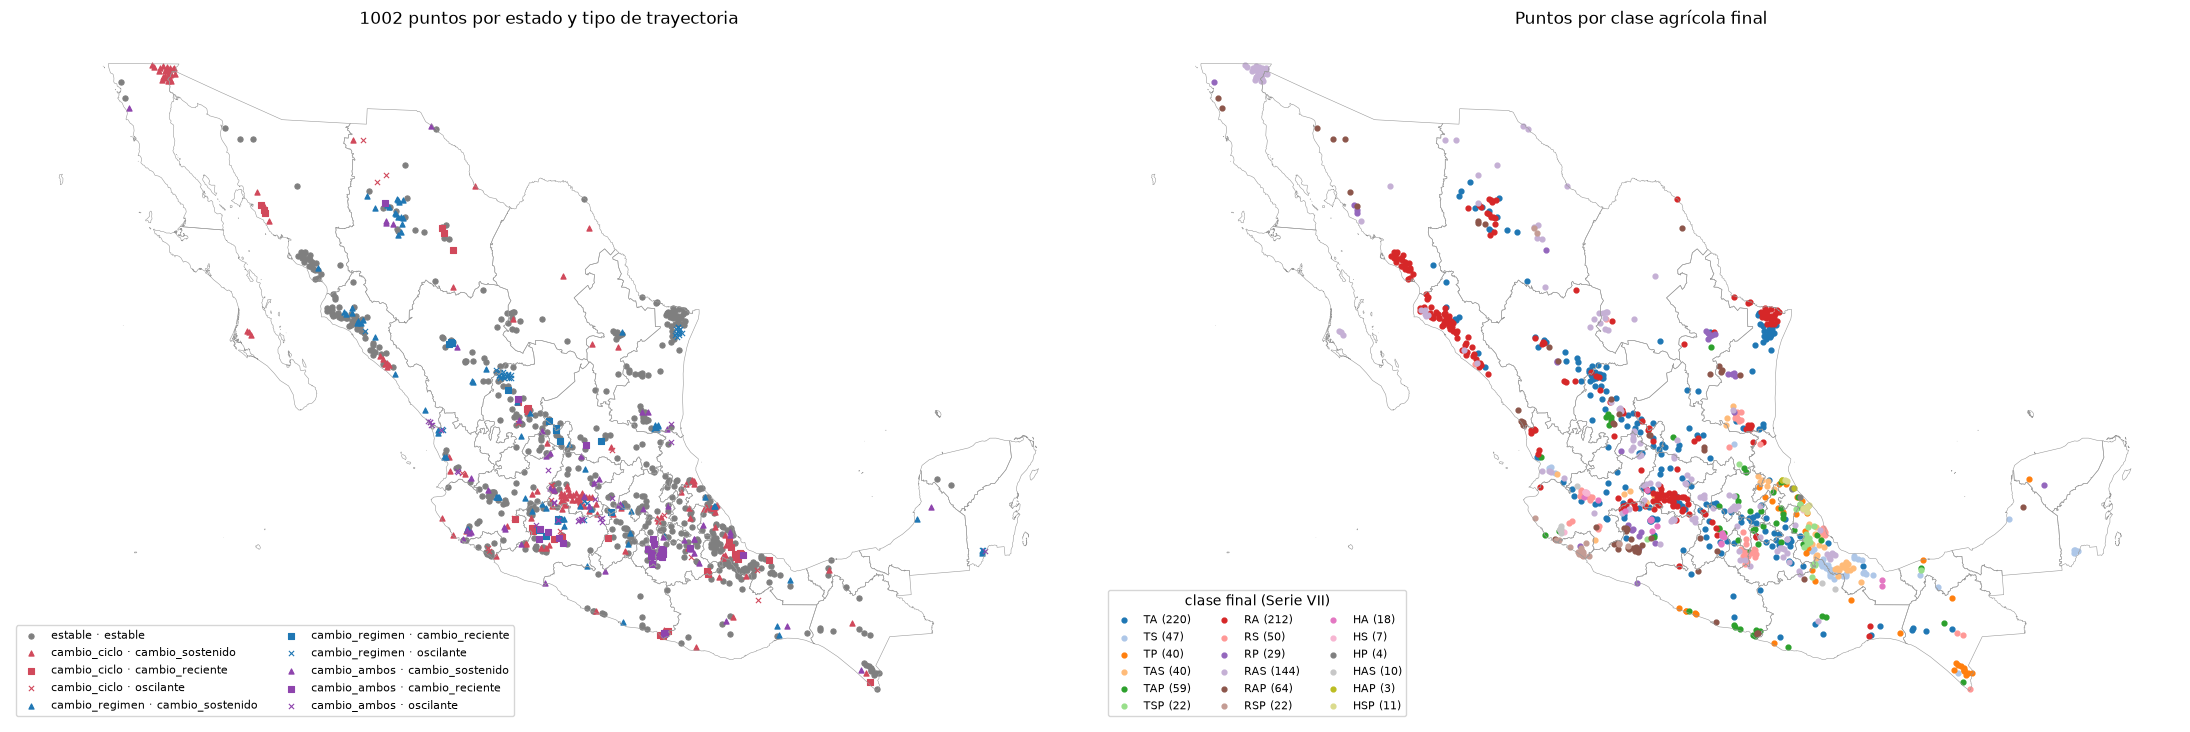

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(22, 9))
ax = axes[0]
ENT_SIMPLE.boundary.plot(ax=ax, color="0.6", lw=0.4)
marcadores = {"estable": "o", "cambio_sostenido": "^", "cambio_reciente": "s", "oscilante": "x"}
for estado in ORDEN_ESTADO:
    for tipo, marcador in marcadores.items():
        sub = muestra[(muestra.estado_trayectoria == estado) & (muestra.tipo_trayectoria == tipo)]
        if len(sub):
            ax.scatter(sub.x, sub.y, s=14, marker=marcador, color=colores_estado[estado],
                       label=f"{estado} · {tipo}", linewidths=0.8)
ax.legend(fontsize=8, loc="lower left", ncols=2)
ax.set_title(f"{len(muestra)} puntos por estado y tipo de trayectoria")
ax.set_axis_off()
ax = axes[1]
ENT_SIMPLE.boundary.plot(ax=ax, color="0.6", lw=0.4)
paleta = plt.get_cmap("tab20")
for i, clase in enumerate(CLASES):
    sub = muestra[muestra.clase_final == clase]
    if len(sub):
        ax.scatter(sub.x, sub.y, s=12, color=paleta(i % 20), label=f"{clase} ({len(sub)})")
ax.legend(fontsize=8, loc="lower left", ncols=3, title="clase final (Serie VII)")
ax.set_title("Puntos por clase agrícola final")
ax.set_axis_off()
plt.tight_layout()
plt.show()

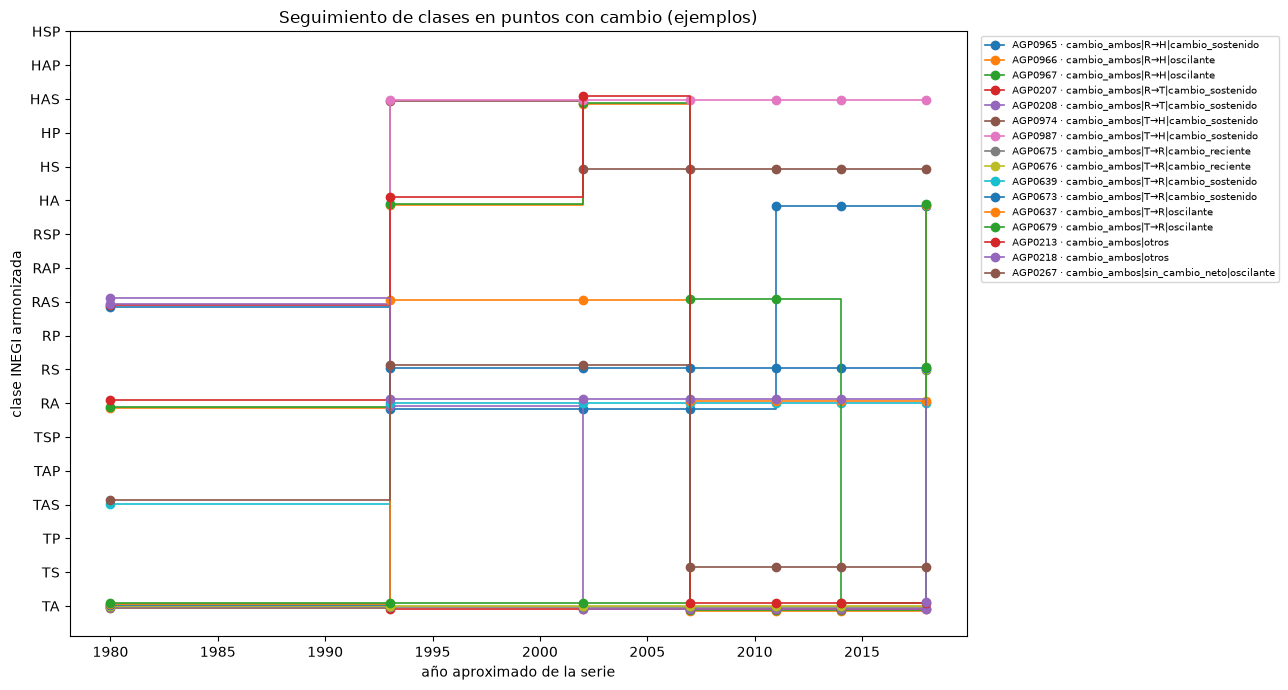

In [33]:
# Ejemplos de trayectorias con cambio: hasta 2 puntos por estrato de cambio más poblado
ejemplos = (muestra[muestra.estado_trayectoria.ne("estable")]
            .groupby("estrato", group_keys=False).head(2)
            .sort_values("estrato").head(16))
pos = {c: i for i, c in enumerate(CLASES)}
fig, ax = plt.subplots(figsize=(13, 7))
for k, (_, fila) in enumerate(ejemplos.iterrows()):
    valores = [pos[fila[f"clase_{s}"]] + (k - len(ejemplos) / 2) * 0.02 for s in SER]
    ax.step([ANIO[s] for s in SER], valores, where="post", marker="o", lw=1.2,
            label=f"{fila.id_punto} · {fila.estrato}")
ax.set_yticks(range(len(CLASES)), CLASES)
ax.set(xlabel="año aproximado de la serie", ylabel="clase INEGI armonizada",
       title="Seguimiento de clases en puntos con cambio (ejemplos)")
ax.legend(fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 11. Exportación

- `data/process/INEGI/puntos_agricolas.gpkg` (capa `puntos_agricolas`, EPSG:4326) y
  `puntos_agricolas.csv`: una fila por punto, formato ancho.
- `data/process/INEGI/puntos_agricolas_seguimiento.csv`: una fila por punto y serie,
  formato largo, para seguir los cambios.

In [34]:
COLS_EXPORT = (
    ["id_punto", "lon", "lat", "x", "y", "clase_final", "descripcion", "regimen_final",
     "ciclo_final", "estado_trayectoria", "tipo_trayectoria", "tipo_tray_regimen",
     "tipo_tray_ciclo", "direccion_regimen", "direccion_ciclo", "trayectoria_clase",
     "clase_inicial", "clase_modal", "n_cambios_clase", "n_cambios_regimen", "n_cambios_ciclo",
     "serie_primer_cambio", "anio_aprox_primer_cambio", "serie_ultimo_cambio",
     "anio_aprox_ultimo_cambio", "series_con_clase_final"]
    + COLS_CLASE + [f"regimen_{s}" for s in SER] + [f"ciclo_{s}" for s in SER]
    + ["dist_borde_min_m", "malla_m", "area_km2", "CVEGEO", "CVE_ENT", "NOM_ENT", "NOM_MUN",
       "modalidad_siap", "siap_sembrada_ha", "siap_sembrada_mod_ha", "siap_valor_mxn",
       "siap_densidad_ha_km2", "consistente_siap", "coherente_siap_regimen",
       "coherente_siap_ciclo", "cambio_coherente_siap", "estrato", "peso_siap",
       "peso_muestreo", "prob_inclusion", "factor_expansion_km2", "respaldo"]
)
salida = muestra[COLS_EXPORT].rename(columns={"x": "x_6372", "y": "y_6372"}).copy()
salida["dist_borde_min_m"] = salida["dist_borde_min_m"].round(1)
for col in salida.select_dtypes("boolean").columns:
    salida[col] = salida[col].astype("object").where(salida[col].notna(), None)

gpd.GeoDataFrame(salida, geometry=gpd.points_from_xy(salida.lon, salida.lat), crs=CRS_SALIDA).to_file(
    PROCESS / "puntos_agricolas.gpkg", layer="puntos_agricolas", driver="GPKG")
salida.to_csv(PROCESS / "puntos_agricolas.csv", index=False)

largo = muestra[["id_punto"] + COLS_CLASE + [f"dist_{s}" for s in SER]].copy()
largo = pd.concat([
    pd.DataFrame({"id_punto": largo["id_punto"], "serie": s, "orden_serie": i + 1,
                  "anio_aprox": ANIO[s], "clase": largo[f"clase_{s}"],
                  "dist_borde_m": largo[f"dist_{s}"].round(1)})
    for i, s in enumerate(SER)
]).sort_values(["id_punto", "orden_serie"]).reset_index(drop=True)
largo["regimen"], largo["ciclo"] = largo.clase.str[0], largo.clase.str[1:]
largo["descripcion"] = largo.clase.map(DESCRIPCION)
anterior = largo.groupby("id_punto")[["clase", "regimen", "ciclo"]].shift()
cambia_reg = anterior.regimen.notna() & largo.regimen.ne(anterior.regimen)
cambia_cic = anterior.ciclo.notna() & largo.ciclo.ne(anterior.ciclo)
largo["clase_anterior"] = anterior.clase
largo["cambio_vs_anterior"] = cambia_reg | cambia_cic
largo["tipo_cambio"] = np.select([cambia_reg & cambia_cic, cambia_reg, cambia_cic],
                                 ["ambos", "regimen", "ciclo"], "")
largo.to_csv(PROCESS / "puntos_agricolas_seguimiento.csv", index=False)

assert len(largo) == 7 * len(salida)
assert (largo.groupby("id_punto")["cambio_vs_anterior"].sum()
        .reindex(salida.id_punto).to_numpy() == salida["n_cambios_clase"].to_numpy()).all()
releido = gpd.read_file(PROCESS / "puntos_agricolas.gpkg")
assert len(releido) == len(salida) and releido.crs.to_epsg() == 4326
for archivo in ("puntos_agricolas.gpkg", "puntos_agricolas.csv", "puntos_agricolas_seguimiento.csv"):
    print(f"{archivo}: {(PROCESS / archivo).stat().st_size / 1024:.0f} KB")
largo[largo.id_punto.isin(muestra.loc[muestra.n_cambios_clase > 0, "id_punto"].head(2))]

puntos_agricolas.gpkg: 616 KB
puntos_agricolas.csv: 495 KB
puntos_agricolas_seguimiento.csv: 533 KB


,id_punto,serie,orden_serie,anio_aprox,clase,dist_borde_m,regimen,ciclo,descripcion,clase_anterior,cambio_vs_anterior,tipo_cambio
1078,AGP0155,I,1,1980,TA,523.9,T,A,AGRICULTURA DE TEMPORAL ANUAL,NaN,False,
1079,AGP0155,II,2,1993,TAP,774.7,T,AP,AGRICULTURA DE TEMPORAL ANUAL Y PERMANENTE,TA,True,ciclo
1080,AGP0155,III,3,2002,TAP,738.1,T,AP,AGRICULTURA DE TEMPORAL ANUAL Y PERMANENTE,TAP,False,
1081,AGP0155,IV,4,2007,TA,268.0,T,A,AGRICULTURA DE TEMPORAL ANUAL,TAP,True,ciclo
1082,AGP0155,V,5,2011,TA,268.0,T,A,AGRICULTURA DE TEMPORAL ANUAL,TA,False,
1083,AGP0155,VI,6,2014,TA,268.0,T,A,AGRICULTURA DE TEMPORAL ANUAL,TA,False,
1084,AGP0155,VII,7,2018,TA,268.0,T,A,AGRICULTURA DE TEMPORAL ANUAL,TA,False,
1085,AGP0156,I,1,1980,TA,1039.0,T,A,AGRICULTURA DE TEMPORAL ANUAL,NaN,False,
1086,AGP0156,II,2,1993,TA,1096.3,T,A,AGRICULTURA DE TEMPORAL ANUAL,TA,False,
1087,AGP0156,III,3,2002,TAP,845.9,T,AP,AGRICULTURA DE TEMPORAL ANUAL Y PERMANENTE,TA,True,ciclo


### Diccionario de columnas (`puntos_agricolas.csv` / `.gpkg`)

| Columna | Descripción |
|---|---|
| `id_punto` | Identificador del punto |
| `lon`, `lat` | Coordenadas WGS84 (EPSG:4326) |
| `x_6372`, `y_6372` | Coordenadas LCC ITRF2008 (EPSG:6372), en m |
| `clase_final`, `descripcion` | Clase INEGI armonizada en la Serie VII (≈2018) y su nombre |
| `regimen_final`, `ciclo_final` | Régimen (R/T/H) y ciclo (A/S/P y combinaciones) en la Serie VII |
| `estado_trayectoria` | `estable`, `cambio_ciclo`, `cambio_regimen`, `cambio_ambos` |
| `tipo_trayectoria`, `tipo_tray_regimen`, `tipo_tray_ciclo` | `estable`, `cambio_sostenido`, `cambio_reciente`, `oscilante` |
| `direccion_regimen`, `direccion_ciclo` | Dirección neta del cambio entre la Serie I y la VII |
| `trayectoria_clase` | Secuencia de clases I→VII |
| `clase_inicial`, `clase_modal` | Clase en la Serie I y la más frecuente |
| `n_cambios_*` | Número de cambios entre series consecutivas |
| `serie_primer_cambio`, `serie_ultimo_cambio`, `anio_aprox_*` | Serie y año aproximado del primer y del último cambio |
| `series_con_clase_final` | Series consecutivas, contando hacia atrás desde la VII, con la clase final |
| `clase_k`, `regimen_k`, `ciclo_k` | Clase, régimen y ciclo en cada serie *k* = I…VII |
| `dist_borde_min_m` | Distancia mínima (m) al borde del polígono agrícola en las 7 series |
| `malla_m`, `area_km2` | Resolución de la malla de origen y área que representa el punto |
| `CVEGEO`, `CVE_ENT`, `NOM_ENT`, `NOM_MUN` | Municipio y entidad (Marco Geoestadístico 2025) |
| `modalidad_siap` | Modalidad SIAP equivalente al régimen final (Riego/Temporal) |
| `siap_sembrada_ha`, `siap_sembrada_mod_ha` | Superficie sembrada anual promedio 2003–2025 del municipio: total y en la modalidad |
| `siap_valor_mxn` | Valor de la producción anual promedio 2021–2025 del municipio (pesos corrientes) |
| `siap_densidad_ha_km2` | Hectáreas sembradas en la modalidad por km² agrícola de la Serie VII del municipio |
| `consistente_siap` | El municipio reporta siembra en la modalidad del punto |
| `coherente_siap_regimen`, `coherente_siap_ciclo`, `cambio_coherente_siap` | Si el cambio (posterior a 2002) concuerda con la tendencia municipal del SIAP 2003–2005 → 2016–2018; vacío si no aplica |
| `estrato` | Estrato de muestreo |
| `peso_siap`, `peso_muestreo` | Peso por productividad municipal y peso final de selección |
| `prob_inclusion`, `factor_expansion_km2` | Probabilidad de inclusión y factor de expansión (km²) para estimaciones Horvitz-Thompson |
| `respaldo` | `clase` o `estado` si el punto se agregó para garantizar esa cobertura |

**`puntos_agricolas_seguimiento.csv`:** `id_punto`, `serie`, `orden_serie`,
`anio_aprox`, `clase`, `regimen`, `ciclo`, `descripcion`, `dist_borde_m`,
`clase_anterior`, `cambio_vs_anterior` y `tipo_cambio` (`ciclo`, `regimen` o `ambos`).

### Limitaciones

- Parte de los cambios pueden ser artefactos de la escala 1:250 000 o de la metodología
  de cada serie, sobre todo las trayectorias `oscilante` y los cambios entre las series
  I y II. Todos van marcados y `cambio_coherente_siap` sirve como contraste.
- El SIAP sólo distingue Riego y Temporal, así que la Humedad se compara contra Temporal.
- Las clases de Humedad (HP, HSP, HAP, …) tienen muy poca superficie persistente; se
  representan con pocos puntos, densificados a 250 m.